# Download and prepare `PA` (2005-2026.09)

**notebook version**: `4` (22 Oct 2026)

## ℹ️ About this notebook

Downloads screened atmospheric pressure `PA` from InfluxDB, **harmonises the units of the two
sources**, merges them, applies the 2012 corrections and writes the product to the external data
folder. It also identifies the barometer from the logger programs, checks the **absolute** level
against the barometric formula, and tests the two hardware boundaries in the record.

Differences from notebooks `01`-`03`:

1. **The sources are stored in different units** (`kPa`, `Pa`) and are harmonised to `kPa` before
   anything else.
2. **No gap-filling.** The record is almost complete and is exported as measured.
3. **The record starts 2005-09-02**, when the archive begins. Nothing earlier is invented, so the
   index does not begin at 2004-01-01.

**Output column:** `PA_T1_47_1`, pressure in **kPa**, measured and corrected, gaps left as `NaN`.
There is **no `FLAG_..._ISFILLED` column**: every non-null record is a measurement.

::: {.callout-important title="Known limitation: a level step at the January 2016 acquisition change"}
The record before the tower logger replacement of January 2016 sits about 0.09 kPa above the record
after it. The step is on the tower barometer, since the two references do not move against each
other. Averaged over 2016 to 2025, the later era agrees with the barometric formula to within
0.03 kPa against both references. Year by year, its departure from the formula against Lägern
grows from +0.017 kPa in 2016 to -0.061 kPa in 2025 and -0.074 kPa in January to September 2026.
The formula is computed from Lägern's own pressure, so it cannot say whether the tower or Lägern
drifts.

The series is exported **as measured**, without a homogenised column: the step is one part in a
thousand, and a second column would change this product and the merged one. To obtain one absolute
level, lower the records before 2016-01-21 by the step. Comparisons within a year and air density
for flux processing are not affected at this size.
:::

`InfluxIO` needs `influxdb-client`, which `uv sync` installs through the `diive[db]` extra.

***

## 📇 Data sources

- `PA_T1_47_1`: exported variable, tower 1, 47 m. `mst` (2005-2021) and `diive` (2022-2026), not
  overlapping.
- `PA_NABEL_H1_2_1`: hut barometer, 2 m, on the **NABEL** acquisition system, independent of the
  tower logger. Diagnostic only. Nominally to the end of 2018, but from July 2018 it repeats the
  tower series and is trimmed there.
- `PA_LAE_MS`: MeteoSwiss Lägern station pressure (2.5 km, 845 m), 2004-2026, from `REFPATH`.
  Diagnostic only; it covers the years after NABEL stops. `hPa`, divided by 10. `TA_LAE_MS` and
  `VP_LAE_MS` from the same file feed the barometric formula.
- `PA_H1_0_1` (2017-2019, kPa) is not used: short, and it overlaps a period in which
  `PA_T1_47_1` is essentially complete.
- **Logger programs**: six CR10X programs (2004-2006) and the CR1000 program of January 2016. They
  name the barometer and its conversion, which the fieldbook does not.
- **GIN fieldbook**: the site maintenance record, read and filtered in the notebook.

Screening: `mst` is ETH data screened with the deprecated MeteoscreeningTool; `diive` is ETH and
[NABEL](https://www.bafu.admin.ch/bafu/en/home/topics/air/luftbelastung/national-air-pollution-monitoring-network--nabel-.html)
data screened with [diive](https://github.com/holukas/diive).
[MeteoSwiss](https://www.meteoswiss.admin.ch/) open data come from `10_REFERENCE`.

## ⚠️ The unit break, and why it is handled first

`meteoscreening_mst` (2005-09-02 to 2021-12-31) stores `PA_T1_47_1` in `kPa`,
`meteoscreening_diive` (from 2022-01-01) in `Pa`: exactly a factor of 1000, with no overlap. The
counts and medians are tabulated under *Before harmonisation*; the medians are not exactly 1000
apart only because they cover different years. Merged as stored, every statistic across the break
would be meaningless and still look like a number.

The harmonisation therefore runs **before the merge** and ignores the calendar:

- The unit is decided **per source from the median**. Surface pressure here (~690 m a.s.l.) is
  about 93 kPa = 930 hPa = 93,000 Pa, so the magnitude is unambiguous.
- The verdict must match the **database unit tag** (`kPa` for `mst`, `Pa` for `diive`, `hPa` for
  NABEL), or the notebook raises.
- The **full converted range** of every source must lie in the plausible band, or the notebook
  raises.

**Output unit is `kPa`**: the FLUXNET convention, the unit `diive`'s FLUXNET formatter documents
(`PA (kPa)`), the one notebook `x-99` declares for EddyPro's `Pa_1_1_1`, and that of the
`11_METEO6` product.

## ⏱️ Timestamp convention

The database stores UTC `TIMESTAMP_END`. `InfluxIO` shifts it by `TIMEZONE_OFFSET_TO_UTC_HOURS` to
local time, and `TimestampSanitizer(output_middle_timestamp=True)` converts it to
`TIMESTAMP_MID`, which the rest of the notebook uses. `START` and `STOP` are local time.

***

## ⚙️ Settings

### Data settings

In [1]:
DIRCONF = r'F:\dev\poet\configs'  # database connection configs
# DIRCONF = r'P:\Flux\RDS_calculations\_scripts\_configs\configs'  # alternative location
TIMEZONE_OFFSET_TO_UTC_HOURS = 1  # local time UTC+01:00 (CET)
REQUIRED_TIME_RESOLUTION = '30min'
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389  # CH-LAE

TARGET = "PA_T1_47_1"           # exported variable, tower 47 m
REFERENCE = "PA_NABEL_H1_2_1"   # hut barometer, diagnostics only, never exported

# PA starts 2005-09-02 and nothing before it is reconstructed, so the index starts there rather
# than at 2004-01-01, which would open with 20 months of nothing.
RECORD_START = '2005-09-02'

# Last record (TIMESTAMP_MID). The file names say 2026.09; the export check asserts it.
PERIOD_END = '2026-09-30 23:45:00'

# 2026 covers January to September only, so statistics that compare calendar years stop here.
LAST_FULL_YEAR = 2025

# Output, in the external data folder, same numeric prefix as this notebook. The name carries
# neither GAPFILLED nor 2004, because the product is neither.
OUTNAME = "05_METEO_PA_2005-2026.09"
OUTPATH = r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS"

# Reference: MeteoSwiss Lägern station pressure (QFE), 2.5 km, 845 m, over the whole record, so
# it covers the years after NABEL stops in 2018. Diagnostic only, never exported. Written by
# 10_REFERENCE/MeteoSwiss_LAE_2004-2026.09.ipynb; addressed by path, so a move breaks this read.
REFPATH = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\10_METEO\10_REFERENCE\MeteoSwiss_LAE_30MIN_2004-2026.09.parquet")
REFCOL = "PA_LAE_MS"     # hPa in the reference file; divided by 10 to kPa where it is used
REFCOL_TA = "TA_LAE_MS"  # deg C, the air temperature of the column between station and tower
REFCOL_VP = "VP_LAE_MS"  # hPa, vapour pressure; humid air is lighter, so the check needs it

# --- Geometry, for the barometric check --------------------------------------------------------
# Pressure falls with height by a law with no free parameter, so these elevations give a
# prediction the measured difference meets or not. Inputs to a test, not to the product.
SITE_BASE_ELEVATION = 689.0  # m a.s.l., tower base
SENSOR_HEIGHT = 47.0         # m above ground, from the field name PA_T1_47_1
LAE_ELEVATION = 845.0        # m a.s.l., MeteoSwiss Laegern (from 10_REFERENCE)
HUT_HEIGHT = 2.0             # m above ground, from the field name PA_NABEL_H1_2_1

# --- Inputs for the sensor-identity section ----------------------------------------------------
# The site maintenance record, exported from GIN. It sits beside the workflow folder because many
# stages read it.
FIELDBOOK = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
             r"\fieldbook_gin\CH-LAE-laegeren-export_20261022.csv")

# Every surviving logger program that measures pressure at this tower, parsed on every run. All six
# CR10X programs carry the barometer; PROGRAM_AFTER is the CR1000 program of January 2016.
_CSI = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
        r"\csi_loggerscripts")
PROGRAMS_CR10X = [_CSI + r"\LAEGEREN.20040526.CSI",
                  _CSI + r"\LAEGEREN.20040810.CSI",
                  _CSI + r"\LAEGEREN.20041228.CSI",
                  _CSI + r"\LAEGEREN.20050818.CSI",
                  _CSI + r"\LAEGEREN.20050914.CSI",
                  _CSI + r"\LAEGEREN.20060524.csi"]
PROGRAM_AFTER = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
                 r"\logger_scripts\ch-lae_idl_t1_47_1-Version_20160118\CH-LAE_iDL_T1_47_1.CR1")

# The tower logger was replaced during the outage that ends on this date. The data, the program
# file name and the fieldbook all give it; asserted below.
ACQUISITION_CHANGE = '2016-01-21'


### Imports

In [2]:
from datetime import datetime
from pathlib import Path
import importlib.metadata
import html
import re
import textwrap

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme('notebook')

import diive as dv
from diive.core.io.db.influx import InfluxIO  # diive's in-house InfluxDB engine (via the diive[db] extra)
from diive.core.times.times import TimestampSanitizer

import warnings

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-22 15:54:09
diive version: v0.93.0


### Captions

Tables carry a caption above, figures one below. Both helpers are copied as-is from notebook `03`.

In [3]:
# Captions. Copied as-is from notebook 03, whose figcap carries the PlaceHolderLayoutEngine fix.
def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure - {text}", width)
    # An engine that still lays the figure out at draw time can make room for a caption itself.
    # plt.tight_layout() does NOT leave one: it executes once and leaves a PlaceHolderLayoutEngine
    # that never runs again, so a caption handed to supxlabel there lands on top of the tick
    # labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12          # inches; one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')

### 🧭 Unit harmonisation helper

`harmonise_to_kpa()` converts only what it can identify with certainty and never looks at the date.
`PA_PLAUSIBLE_KPA` (85-100 kPa) is deliberately wide: recorded extremes here are 89.4-95.5 kPa, and
the band only has to separate `kPa`, `hPa` and `Pa`.

In [4]:
# Plausible surface pressure at CH-LAE (~690 m a.s.l.). Wide enough to accept any real weather,
# far too narrow to accept a value that is off by a factor of 10 or 1000.
PA_PLAUSIBLE_KPA = (85.0, 100.0)

UNIT_FACTORS_TO_KPA = {'kPa': 1.0, 'hPa': 0.1, 'Pa': 0.001}


def harmonise_to_kpa(series: pd.Series, source: str, declared_unit: str | None = None) -> pd.Series:
    """Convert a pressure series to kPa, identifying its unit from the data itself.

    The unit is decided by magnitude, NOT by date: the median is multiplied by each candidate
    factor and exactly one result must land inside `PA_PLAUSIBLE_KPA`. `declared_unit` is the
    unit tag stored alongside the series in the database; when given it must agree with the
    magnitude verdict.

    Raises ValueError if the unit is ambiguous, if the declared and detected units disagree, or
    if any converted value falls outside the plausible band. Silently returning a series that is
    off by a factor of 1000 is the one outcome that must never happen.
    """
    s = series.dropna()
    if s.empty:
        raise ValueError(f"{source}: no data, cannot determine unit.")

    lo, hi = PA_PLAUSIBLE_KPA
    median = float(s.median())
    matches = [u for u, f in UNIT_FACTORS_TO_KPA.items() if lo <= median * f <= hi]
    if len(matches) != 1:
        raise ValueError(
            f"{source}: median {median:,.2f} is consistent with {matches or 'no'} unit(s), "
            f"expected exactly one. Surface pressure here is ~93 kPa / ~930 hPa / ~93,000 Pa.")
    detected = matches[0]

    if declared_unit is not None and declared_unit != detected:
        raise ValueError(
            f"{source}: the database declares '{declared_unit}' but the magnitude says "
            f"'{detected}' (median {median:,.2f}). Refusing to guess - check the source.")

    factor = UNIT_FACTORS_TO_KPA[detected]
    out = series * factor

    converted = out.dropna()
    if not (lo <= converted.min() and converted.max() <= hi):
        raise ValueError(
            f"{source}: after converting {detected} -> kPa the range is "
            f"{converted.min():.2f}..{converted.max():.2f} kPa, outside the plausible "
            f"{lo}..{hi} kPa. Not exporting this.")

    print(f"  {source:<26} {detected:>3} -> kPa (x{factor:g})   n={len(converted):>7,}   "
          f"median {float(converted.median()):7.3f}   "
          f"range {converted.min():.2f}..{converted.max():.2f}")
    return out

### 🔌 Connect to database

In [5]:
dbc = InfluxIO(dirconf=DIRCONF)

> Reading configuration files was successful.

v Connection to database works.

***

## ⬇️ Download

Three series are downloaded: the target from both data versions, and the NABEL reference. Each
series' database unit tag is passed to `harmonise_to_kpa()` as `declared_unit`.

In [6]:
%%time

BUCKET = 'ch-lae_processed'
MEASUREMENTS = ['PA']


def download(fields, start, stop, data_version):
    data, _, _ = dbc.download(
        bucket=BUCKET, measurements=MEASUREMENTS, fields=fields,
        start=start,  # the start date itself IS included
        stop=stop,    # the stop date itself IS NOT included
        timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
        data_version=data_version)
    return TimestampSanitizer(data=data, output_middle_timestamp=True,
                              nominal_freq=REQUIRED_TIME_RESOLUTION).get()


mst_pa = download([TARGET], '2004-01-01 00:00:01', '2022-01-01 00:00:01', 'meteoscreening_mst')
diive_pa = download([TARGET, REFERENCE], '2004-01-01 00:00:01',
                    '2026-10-01 00:00:01',  # includes the record ending 1 Oct 00:00
                    'meteoscreening_diive')

print(f"mst   {TARGET}: {mst_pa[TARGET].notna().sum():,} records")
print(f"diive {TARGET}: {diive_pa[TARGET].notna().sum():,} records")
print(f"diive {REFERENCE}: {diive_pa[REFERENCE].notna().sum():,} records")

> DOWNLOADING from bucket ch-lae_processed: variables ['PA_T1_47_1'] from measurements ['PA'], 
data version ['meteoscreening_mst'], between 2004-01-01 00:00:01 and 2022-01-01 00:00:01 (timezone 
offset to UTC 1)

> Downloaded data for 1 variables:

> <-- PA_T1_47_1: 283,395 records from 2005-09-02 10:30:00 to 2022-01-01 00:00:00, time resolution
30min (freq tag: 30min)

> DOWNLOADING from bucket ch-lae_processed: variables ['PA_T1_47_1', 'PA_NABEL_H1_2_1'] from 
measurements ['PA'], data version ['meteoscreening_diive'], between 2004-01-01 00:00:01 and 
2026-10-01 00:00:01 (timezone offset to UTC 1)

> Downloaded data for 2 variables:

> <-- PA_T1_47_1: 83,116 records from 2022-01-01 00:30:00 to 2026-10-01 00:00:00, time resolution 
30min (freq tag: 30min)

> <-- PA_NABEL_H1_2_1: 262,305 records from 2004-01-01 00:30:00 to 2019-01-01 00:00:00, time 
resolution 30min (freq tag: 30min)

mst   PA_T1_47_1: 283,395 records
diive PA_T1_47_1: 83,116 records
diive PA_NABEL_H1_2_1: 262,305 records
CPU times: total: 12.4 s
Wall time: 16.7 s


In [7]:
# The unit each series is stored with, straight from the database tags.
def declared_unit(field, data_version):
    tags = dbc.show_field_overview(bucket=BUCKET, measurement='PA', field=field,
                                   data_version=data_version, verbose=False)['tags']
    units = tags['units']
    if len(units) != 1:
        raise ValueError(f"{field} ({data_version}): expected one unit tag, found {units}.")
    return units[0]


UNIT_MST = declared_unit(TARGET, 'meteoscreening_mst')
UNIT_DIIVE = declared_unit(TARGET, 'meteoscreening_diive')
UNIT_NABEL = declared_unit(REFERENCE, 'meteoscreening_diive')
print(f"database unit tags -> mst: {UNIT_MST} | diive: {UNIT_DIIVE} | NABEL: {UNIT_NABEL}")

database unit tags -> mst: kPa | diive: Pa | NABEL: hPa


### 📋 Table: downloaded series before harmonisation

The raw values, shown only here to document the break.

In [8]:
_raw = pd.DataFrame({
    'n': [mst_pa[TARGET].notna().sum(), diive_pa[TARGET].notna().sum(),
          diive_pa[REFERENCE].notna().sum()],
    'first': [mst_pa[TARGET].first_valid_index(), diive_pa[TARGET].first_valid_index(),
              diive_pa[REFERENCE].first_valid_index()],
    'last': [mst_pa[TARGET].last_valid_index(), diive_pa[TARGET].last_valid_index(),
             diive_pa[REFERENCE].last_valid_index()],
    'median_as_stored': [mst_pa[TARGET].median(), diive_pa[TARGET].median(),
                         diive_pa[REFERENCE].median()],
    'unit_tag': [UNIT_MST, UNIT_DIIVE, UNIT_NABEL],
}, index=[f'{TARGET} (mst)', f'{TARGET} (diive)', f'{REFERENCE} (diive)'])
tabcap(f"the three downloaded series exactly as the database stores them, before any conversion. "
       f"The two {TARGET} rows describe the same quantity at the same place and their medians "
       f"differ by a factor of a thousand: the unit break this notebook handles first")
display(_raw)
print(f"ratio of the two {TARGET} medians: "
      f"{float(diive_pa[TARGET].median() / mst_pa[TARGET].median()):,.1f}")

Table - the three downloaded series exactly as the database stores them, before any conversion. The
two PA_T1_47_1 rows describe the same quantity at the same place and their medians differ by a
factor of a thousand: the unit break this notebook handles first



,n,first,last,median_as_stored,unit_tag
PA_T1_47_1 (mst),283395,2005-09-02 10:15:00,2021-12-31 23:45:00,93.326965,kPa
PA_T1_47_1 (diive),83116,2022-01-01 00:15:00,2026-09-30 23:45:00,93241.542833,Pa
PA_NABEL_H1_2_1 (diive),262305,2004-01-01 00:15:00,2018-12-31 23:45:00,937.350000,hPa


ratio of the two PA_T1_47_1 medians: 999.1


***

## 🧮 Unit harmonisation

Every series is converted to `kPa` here, **before** the merge and before any plot or statistic.

In [9]:
print("Harmonising to kPa (unit detected from magnitude, cross-checked against the database tag):")
pa_mst = harmonise_to_kpa(mst_pa[TARGET], f'{TARGET} (mst)', declared_unit=UNIT_MST)
pa_diive = harmonise_to_kpa(diive_pa[TARGET], f'{TARGET} (diive)', declared_unit=UNIT_DIIVE)
pa_nabel = harmonise_to_kpa(diive_pa[REFERENCE], f'{REFERENCE}', declared_unit=UNIT_NABEL)

Harmonising to kPa (unit detected from magnitude, cross-checked against the database tag):
  PA_T1_47_1 (mst)           kPa -> kPa (x1)   n=283,395   median  93.327   range 89.45..95.54
  PA_T1_47_1 (diive)          Pa -> kPa (x0.001)   n= 83,116   median  93.242   range 89.54..95.34
  PA_NABEL_H1_2_1            hPa -> kPa (x0.1)   n=262,305   median  93.735   range 89.79..96.03


### The guard actually guards

Declaring the `Pa` source as `kPa` must raise. Anything other than a caught `ValueError` here means
the rest of the notebook cannot be trusted.

In [10]:
try:
    harmonise_to_kpa(diive_pa[TARGET], f'{TARGET} (diive)', declared_unit='kPa')
    raise AssertionError("harmonise_to_kpa accepted a wrong declared unit - the guard is broken.")
except ValueError as exc:
    print(f"OK, raised as intended:\n  {exc}")

OK, raised as intended:
  PA_T1_47_1 (diive): the database declares 'kPa' but the magnitude says 'Pa' (median 93,241.54). Refusing to guess - check the source.


### Merge onto one continuous 30MIN index

The index runs from the first measurement (2005-09-02) to `PERIOD_END`. The sources do not overlap;
`combine_first` rather than `concat` makes any future overlap resolve to `mst` instead of
duplicating timestamps.

#### 📋 Table: merged series on the 30MIN index

In [11]:
full_index = pd.date_range(f'{RECORD_START} 00:15:00', PERIOD_END,
                           freq='30min', name='TIMESTAMP_MIDDLE')
pa_2005_2026 = pd.DataFrame(index=full_index)
pa_2005_2026[TARGET] = pa_mst.combine_first(pa_diive).reindex(full_index)
pa_2005_2026[REFERENCE] = pa_nabel.reindex(full_index)

print(f"{TARGET}: {pa_2005_2026[TARGET].notna().sum():,} of {len(pa_2005_2026):,} records "
      f"({100 * pa_2005_2026[TARGET].notna().mean():.2f}%)")
print(f"first measurement: {pa_2005_2026[TARGET].first_valid_index()}")
tabcap("the merged series on one continuous 30MIN index. The two sources do not overlap, so "
       "combine_first joins two screenings of one measurement and fills nothing")
pa_2005_2026

PA_T1_47_1: 366,511 of 369,552 records (99.18%)
first measurement: 2005-09-02 10:15:00
Table - the merged series on one continuous 30MIN index. The two sources do not overlap, so
combine_first joins two screenings of one measurement and fills nothing



,PA_T1_47_1,PA_NABEL_H1_2_1
TIMESTAMP_MIDDLE,,
2005-09-02 00:15:00,NaN,94.184167
2005-09-02 00:45:00,NaN,94.197500
2005-09-02 01:15:00,NaN,94.210833
2005-09-02 01:45:00,NaN,94.227500
2005-09-02 02:15:00,NaN,94.220833
...,...,...
2026-09-30 21:45:00,93.616374,NaN
2026-09-30 22:15:00,93.619444,NaN
2026-09-30 22:45:00,93.620568,NaN


### 📋 Table: the two sources after harmonisation

Both sources now sit at about 93.2 to 93.3 kPa.

In [12]:
_harm = pd.DataFrame({
    'n': [pa_mst.notna().sum(), pa_diive.notna().sum()],
    'first': [pa_mst.first_valid_index(), pa_diive.first_valid_index()],
    'last': [pa_mst.last_valid_index(), pa_diive.last_valid_index()],
    'median_kPa': [pa_mst.median().round(3), pa_diive.median().round(3)],
    'min_kPa': [pa_mst.min().round(3), pa_diive.min().round(3)],
    'max_kPa': [pa_mst.max().round(3), pa_diive.max().round(3)],
}, index=['meteoscreening_mst', 'meteoscreening_diive'])
tabcap("the two sources after conversion to kPa. Both sit at about 93.2 to 93.3 kPa; the remaining "
       "difference between the medians is weather, because the two cover different years")
display(_harm)

_gap = abs(float(pa_mst.median()) - float(pa_diive.median()))
print(f"difference between the two source medians: {_gap:.3f} kPa "
      f"(was a factor of ~1000 before harmonisation)")
assert _gap < 1.0, "Sources still disagree by more than 1 kPa - harmonisation did not work."

Table - the two sources after conversion to kPa. Both sit at about 93.3 kPa; the remaining
difference between the medians is weather, because the two cover different years



,n,first,last,median_kPa,min_kPa,max_kPa
meteoscreening_mst,283395,2005-09-02 10:15:00,2021-12-31 23:45:00,93.327,89.446,95.543
meteoscreening_diive,83116,2022-01-01 00:15:00,2026-09-30 23:45:00,93.242,89.540,95.340


difference between the two source medians: 0.085 kPa (was a factor of ~1000 before harmonisation)


### The NABEL reference stops being independent

From **July 2018** the values stored under `PA_NABEL_H1_2_1` reproduce `PA_T1_47_1` to the fifth
decimal, which two barometers 45 m apart never do: the NABEL barometer had stopped and its slot was
back-filled with the tower series. A copied reference makes every comparison circular while looking
like perfect agreement. The test is a run of consecutive records agreeing to better than
0.0001 kPa; the reference is cut where the first run begins. MeteoSwiss Lägern covers the years
after.

In [13]:
def independent_until(target: pd.Series, reference: pd.Series, tol: float = 1e-4,
                      min_run: int = 48) -> pd.Timestamp | None:
    """The first timestamp from which `reference` merely repeats `target`, or None.

    Two barometers separated by 45 m of air agree to a few hundredths of a kPa and never to five
    decimal places, so a run of `min_run` consecutive records inside `tol` is not agreement, it is
    the same numbers twice. Returns None when no such run exists, which is the answer for a
    reference that is doing its job.
    """
    both = pd.concat([target.rename('t'), reference.rename('r')], axis=1, sort=False).dropna()
    if both.empty:
        raise ValueError("target and reference never overlap - there is nothing to test.")
    same = (both['t'] - both['r']).abs() < tol
    run = same.groupby((~same).cumsum()).transform('sum').where(same, 0)
    return both.index[run >= min_run][0] if (run >= min_run).any() else None


REF_COPY_FROM = independent_until(pa_2005_2026[TARGET], pa_2005_2026[REFERENCE])
_before_n = int(pa_2005_2026[REFERENCE].notna().sum())
if REF_COPY_FROM is not None:
    print(f"{REFERENCE} stops being independent at {REF_COPY_FROM} - trimming it there.")
    pa_2005_2026.loc[REF_COPY_FROM:, REFERENCE] = np.nan
_after_n = int(pa_2005_2026[REFERENCE].notna().sum())
print(f"{REFERENCE}: {_before_n:,} -> {_after_n:,} records "
      f"({_before_n - _after_n:,} dropped), now ending "
      f"{pa_2005_2026[REFERENCE].last_valid_index()}")

# The guards guard. The test must fire on a series that IS a copy, and must stay silent on the
# trimmed reference - a test that fired on everything would be as useless as one that never fires.
assert independent_until(pa_2005_2026[TARGET], pa_2005_2026[TARGET].copy()) is not None, \
    "(!) the independence test did not fire on an exact copy of the target"
assert independent_until(pa_2005_2026[TARGET], pa_2005_2026[REFERENCE]) is None, \
    "(!) the reference still repeats the target after trimming"
print("OK: the test fires on a copy and is silent on the trimmed reference.")

PA_NABEL_H1_2_1 stops being independent at 2018-07-03 08:45:00 - trimming it there.
PA_NABEL_H1_2_1: 233,168 -> 224,449 records (8,719 dropped), now ending 2018-07-03 08:15:00
OK: the test fires on a copy and is silent on the trimmed reference.


### 📊 Plot: the merged series

`PA` has almost no daily cycle, so the heatmap is a **coverage** plot. A unit or level problem would
show in the time series.

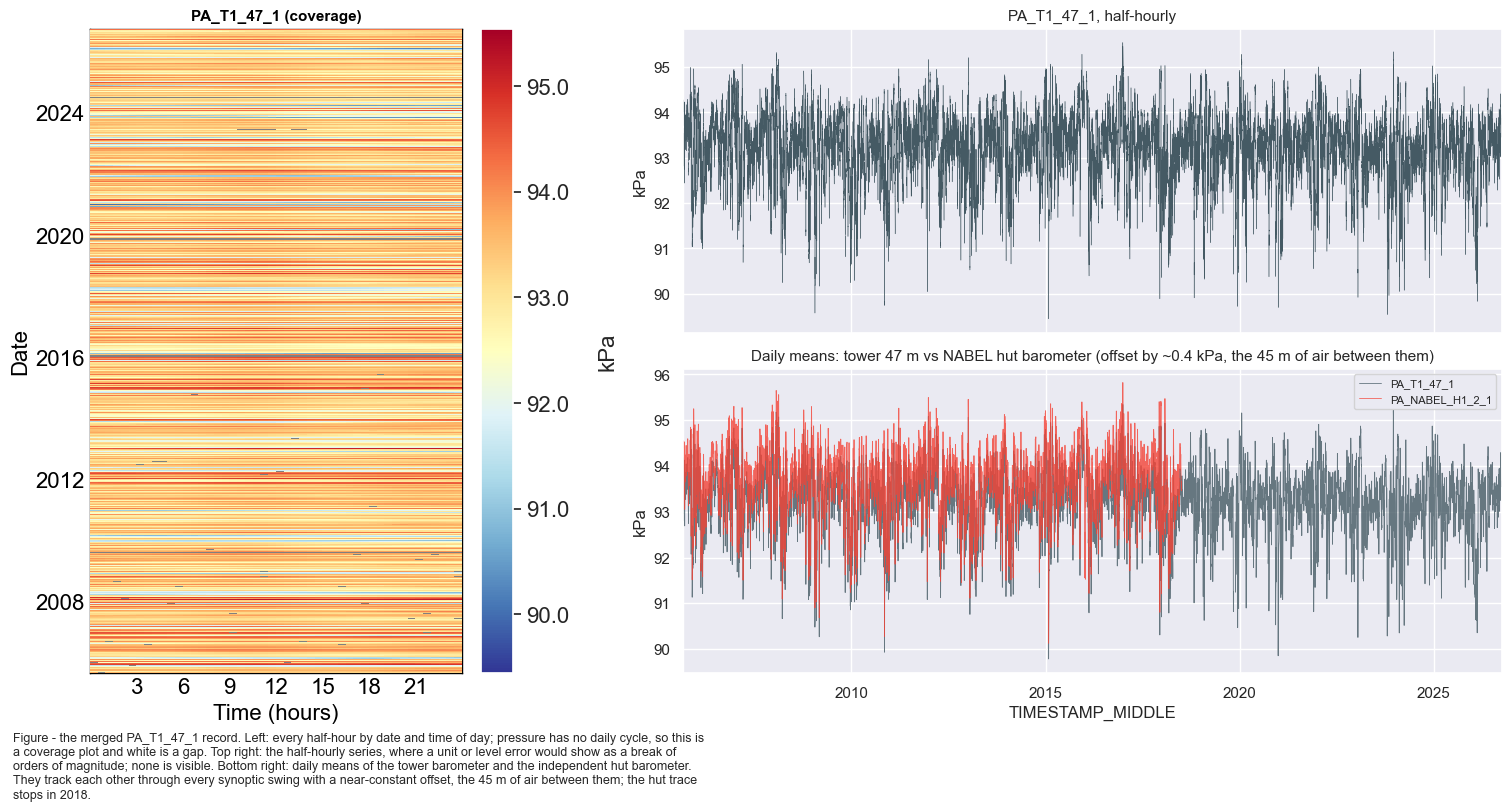

In [14]:
fig = plt.figure(figsize=(15, 8), dpi=100, layout='constrained')
gs = gridspec.GridSpec(2, 2, width_ratios=[1, 2.2], figure=fig)
ax_hm = fig.add_subplot(gs[:, 0])
ax_ts = fig.add_subplot(gs[0, 1])
ax_ref = fig.add_subplot(gs[1, 1], sharex=ax_ts)

dv.plotting.HeatmapDateTime(series=pa_2005_2026[TARGET]).plot(
    ax=ax_hm, cb_digits_after_comma=1, zlabel='kPa',
    format_style=dv.plotting.FormatStyle(title=f'{TARGET} (coverage)', title_fontsize=11))

pa_2005_2026[TARGET].plot(ax=ax_ts, lw=0.3, color='#455A64')
ax_ts.set_ylabel('kPa')
ax_ts.set_title(f'{TARGET}, half-hourly', fontsize=11)

pa_2005_2026[[TARGET, REFERENCE]].resample('1D').mean().plot(
    ax=ax_ref, lw=0.6, color=['#455A64', '#F44336'], alpha=.8)
ax_ref.set_ylabel('kPa')
ax_ref.set_title('Daily means: tower 47 m vs NABEL hut barometer '
                 '(offset by ~0.4 kPa, the 45 m of air between them)', fontsize=11)
ax_ref.legend(fontsize=8)
figcap(fig, f"the merged {TARGET} record. Left: every half-hour by date and time of day; pressure "
            f"has no daily cycle, so this is a coverage plot and white is a gap. Top right: the "
            f"half-hourly series, where a unit or level error would show as a break of orders of "
            f"magnitude; none is visible. Bottom right: daily means of the tower barometer and the "
            f"independent hut barometer. They track each other through every synoptic swing with a "
            f"near-constant offset, the 45 m of air between them; the hut trace stops in 2018.")

***

## ✴️ Corrections

### The reference series, and why they make these diagnostics possible

Neither reference is on the tower logger, which is what judging a tower-logger fault requires.
`PA_NABEL_H1_2_1` (hut, 2 m) runs from 2005 to mid-2018 and covers the 2012 faults. The tower barometer,
45 m higher, reads a near-constant amount lower; adding that offset, computed here and checked
against the barometric formula later, turns NABEL into a **predicted tower pressure**. Undisturbed,
the residual is a few hundredths of a kPa. After 2018, **MeteoSwiss Lägern** is the second
reference.

In [15]:
OFFSET = float((pa_2005_2026[TARGET] - pa_2005_2026[REFERENCE]).median())
reference = pa_2005_2026[REFERENCE] + OFFSET   # NABEL expressed as expected tower pressure

print(f"median(tower - NABEL) = {OFFSET:+.4f} kPa")
print("  the barometric formula is applied to this properly in the sensor section below; "
      "here the offset is only a working constant for the 2012 residual")

_res = (pa_2005_2026[TARGET] - reference).abs()
_quiet = _res.loc['2012-06-01':'2012-07-25']
BASELINE_P999 = float(_quiet.quantile(0.999))
print(f"\nundisturbed agreement (1 Jun - 25 Jul 2012): median {float(_quiet.median()):.4f} kPa, "
      f"p99 {float(_quiet.quantile(0.99)):.4f}, p99.9 {BASELINE_P999:.4f}")
print(f"whole-record median |residual|: {float(_res.median()):.4f} kPa")

median(tower - NABEL) = -0.3990 kPa
  the barometric formula is applied to this properly in the sensor section below; here the offset is only a working constant for the 2012 residual

undisturbed agreement (1 Jun - 25 Jul 2012): median 0.0433 kPa, p99 0.0941, p99.9 0.1370
whole-record median |residual|: 0.0340 kPa


### Timestamp shift in August 2012

**Info from fieldbook entry 17 Aug 2012:**
>   adjusted the logger date and time. On Servertime (Computer System Time) 17.08.2012 12:31.42 the loggertime was 16.08.2012 08:06:00. Synchronized time at 17.08.2012 11:40:00 servertime. The logger data aquisition on the moxa embedded was restarted

`PA_T1_47_1` is on that logger (same acquisition system as `SW_IN_T1_47_1` and `TA_T1_47_1`), so
the `+15.5 h` correction of notebooks `01`-`03` is applied.

::: {.callout-important title="Why the lag diagnostic works for pressure"}
Pressure has almost no diurnal cycle (the semidiurnal tide is ~1-2 hPa against synoptic swings of
tens of hPa). The lag search works on the **synoptic** signal instead: pressure wanders by 1-3 kPa
over a few days, so a 15.5 h shift against an *independent barometer* leaves a large residual.
Without `PA_NABEL_H1_2_1`, which is not on the faulty logger, the test would be underpowered.

| date | best lag | RMSE at best lag | RMSE at zero lag |
|---|---|---|---|
| Jun 2012 (baseline) | 0 | 0.03 | 0.03 |
| 2012-07-27 | -1.0 h | 0.057 | 0.063 |
| 2012-07-29 | +1.0 h | 0.031 | 0.043 |
| 2012-07-30 | +5.0 h | 0.085 | 0.168 |
| 2012-07-31 | +29.0 h | 0.086 | 0.341 |
| 2012-08-06 | -31.5 h | 0.137 | 0.653 |
| 2012-08-07 | -35.5 h | 0.066 | 0.945 |
| **2012-08-11** | **+14.0 h** | **0.026** | 0.322 |
| **2012-08-15** | **+15.5 h** | **0.072** | 0.540 |
| **2012-08-16** | **+15.5 h** | **0.046** | 0.218 |
| 2012-08-18 | (alias) | 0.015 | 0.068 |

(RMSE in kPa against the NABEL barometer; lags searched over +/-48 h in 30 min steps.)

- **15-16 August** lock onto exactly `+15.5 h`, as in `SW_IN` and `TA`: the logger clock.
- **30 July to 9 August** does not recover at any lag: not a clock problem (next section).
- Lags of 24-48 h are aliases of the multi-day autocorrelation and are ignored.
:::

With no diurnal band to return to midday, the correction is validated by the residual against
NABEL, which must fall to the undisturbed baseline.

#### 📋 Table: daily RMSE before and after the shift

In [16]:
ISSUE_START = '2012-08-09 00:00'
ISSUE_END = '2012-08-17 00:00'
SHIFT_HOURS = 15.5

_df = pa_2005_2026.copy()
_before = _df[TARGET].copy()   # kept for the before/after comparison below

# Take the mis-stamped block and move it onto the correct time axis.
_series_shifted = _df.loc[ISSUE_START:ISSUE_END, TARGET].dropna()
_series_shifted.index = _series_shifted.index + pd.Timedelta(hours=SHIFT_HOURS)

# Clear everything between the start of the issue and the last shifted timestamp, then write the
# corrected values back. Same procedure as notebooks 01-03.
_df.loc[ISSUE_START:_series_shifted.index[-1], TARGET] = np.nan
_df.loc[_series_shifted.index, TARGET] = _series_shifted

print(f"shifted {len(_series_shifted):,} records by +{SHIFT_HOURS} h")
print(f"last shifted timestamp (corrected axis): {_series_shifted.index[-1]}")

# Validation: daily RMSE against the NABEL barometer, before vs after.
_rows = []
for _day in pd.date_range('2012-08-09', '2012-08-18', freq='D'):
    _d = _day.strftime('%Y-%m-%d')

    def _rmse(series):
        _x, _y = series.loc[_d], reference.loc[_d]
        _ok = _x.notna() & _y.notna()
        return float(np.sqrt(((_x[_ok] - _y[_ok]) ** 2).mean())) if _ok.sum() >= 12 else np.nan

    _rows.append((_d, _rmse(_before), _rmse(_df[TARGET])))

_check = pd.DataFrame(_rows, columns=['date', 'RMSE_before_kPa', 'RMSE_after_kPa']).set_index('date')
_check['improvement'] = (_check.RMSE_before_kPa - _check.RMSE_after_kPa).round(3)
tabcap("daily root-mean-square difference between the tower and hut barometers over the affected "
       "days, before and after the timestamp shift. Undisturbed, the two agree to about 0.04 kPa, "
       "so an 'after' value near that means the correction landed")
display(_check.round(3))
print("Undisturbed agreement is about 0.04 kPa, so 'after' values near 0.05 kPa mean the "
      "correction landed.")

shifted 376 records by +15.5 h
last shifted timestamp (corrected axis): 2012-08-17 11:15:00
Table - daily root-mean-square difference between the tower and hut barometers over the affected
days, before and after the timestamp shift. Undisturbed, the two agree to about 0.04 kPa, so an
'after' value near that means the correction landed



,RMSE_before_kPa,RMSE_after_kPa,improvement
date,,,
2012-08-09,0.066,0.080,-0.014
2012-08-10,0.135,0.054,0.081
2012-08-11,0.322,0.047,0.275
2012-08-12,0.092,0.054,0.038
2012-08-13,0.104,0.063,0.041
2012-08-14,0.070,0.067,0.003
2012-08-15,0.540,0.074,0.466
2012-08-16,0.218,0.047,0.171
2012-08-17,0.074,0.062,0.013


Undisturbed agreement is about 0.04 kPa, so 'after' values near 0.05 kPa mean the correction landed.


#### 📊 Plot: the August 2012 shift, before and after

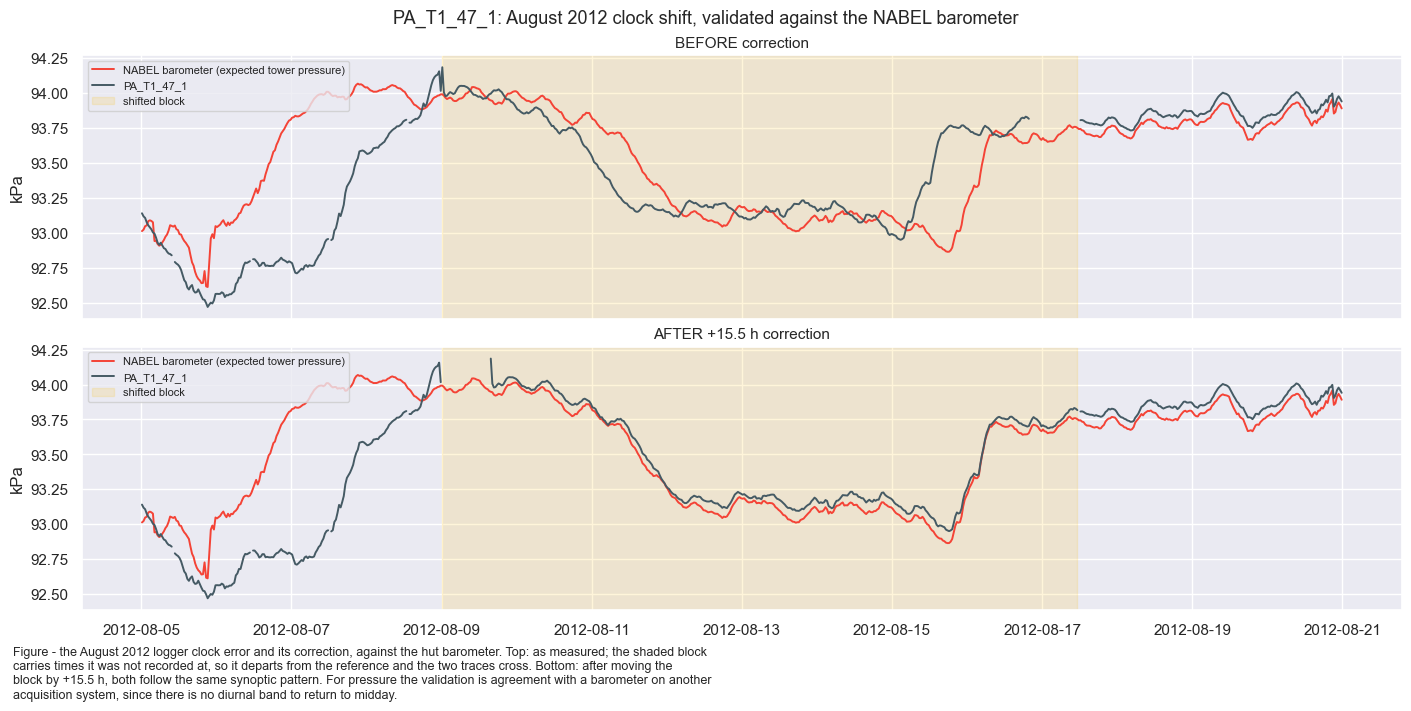

In [17]:
# Visual check: tower vs reference around the shift, before and after.
fig, axs = plt.subplots(nrows=2, figsize=(14, 7), dpi=100, layout='constrained',
                        sharex=True, sharey=True)
fig.suptitle(f'{TARGET}: August 2012 clock shift, validated against the NABEL barometer',
             fontsize=13)
_win = slice('2012-08-05', '2012-08-20')

for _ax, _series, _title in [(axs[0], _before, 'BEFORE correction'),
                             (axs[1], _df[TARGET], f'AFTER +{SHIFT_HOURS} h correction')]:
    _ax.plot(reference.loc[_win].index, reference.loc[_win].values,
             color='#F44336', lw=1.4, label='NABEL barometer (expected tower pressure)')
    _ax.plot(_series.loc[_win].index, _series.loc[_win].values,
             color='#455A64', lw=1.4, label=TARGET)
    _ax.axvspan(pd.Timestamp('2012-08-09'), pd.Timestamp('2012-08-17 11:15'),
                color='#FFC107', alpha=.15, label='shifted block')
    _ax.set_title(_title, fontsize=11)
    _ax.set_ylabel('kPa')
    _ax.legend(fontsize=8, loc='upper left')
figcap(fig, f"the August 2012 logger clock error and its correction, against the hut barometer. "
            f"Top: as measured; the shaded block carries times it was not recorded at, so it "
            f"departs from the reference and the two traces cross. Bottom: after moving the block "
            f"by +{SHIFT_HOURS} h, both follow the same synoptic pattern. For pressure the "
            f"validation is agreement with a barometer on another acquisition system, since there "
            f"is no diurnal band to return to midday.")

In [18]:
pa_2005_2026 = _df.copy()
pa_2005_2026

,PA_T1_47_1,PA_NABEL_H1_2_1
TIMESTAMP_MIDDLE,,
2005-09-02 00:15:00,NaN,94.184167
2005-09-02 00:45:00,NaN,94.197500
2005-09-02 01:15:00,NaN,94.210833
2005-09-02 01:45:00,NaN,94.227500
2005-09-02 02:15:00,NaN,94.220833
...,...,...
2026-09-30 21:45:00,93.616374,NaN
2026-09-30 22:15:00,93.619444,NaN
2026-09-30 22:45:00,93.620568,NaN


### Damaged periods in 2012

Two periods cannot be repaired by a shift and are removed. They are the faults removed in
`01`-`03`, but **the windows are derived from `PA`'s own residual** against NABEL, on the
**corrected** time axis, in half-day blocks. Undisturbed, |residual| stays near 0.04 kPa
(p99.9 = 0.137 kPa, 1 Jun to 25 Jul 2012); `*` marks blocks above that:

| block (corrected axis) | mean abs. residual | verdict |
|---|---|---|
| 2012-07-29 all day | 0.039 / 0.045 | clean |
| 2012-07-30 00:00-12:00 | 0.035 | clean |
| **2012-07-30 12:00-24:00** | **0.177** | * fault begins |
| 2012-07-31 00:00-12:00 | 0.383 | * |
| 2012-08-07 00:00-12:00 | 1.119 | * worst |
| 2012-08-09 12:00-24:00 | 0.065 (max 0.236) | * last bad block |
| **2012-08-10 00:00-12:00** | **0.036** | clean, fault over |
| 2012-10-28, 2012-10-29 | 0.006 to 0.017 | **clean** (best days in the record) |
| **2012-10-30 00:00-12:00** | **0.198** | * second fault begins |
| 2012-11-01 00:00-12:00 | 2.365 | * worst |
| 2012-11-09 00:00-12:00 | 0.115 | * last bad block |
| **2012-11-09 12:00-24:00** | **0.046** | clean, fault over |

The fieldbook gives the causes (see also notebooks `01` and `02`):

> **09.08.2012** Fixed the power problem on the tower: replaced battery and replaced some fuses
> (there were many falsely placed or broken) and replaced the whole power supply
>
> **01.11.2012** Checked Forestfloor and Hut for broken sensors due to fallen trees and big branches
>
> **06.11.2012** checked all sensor cables. especialy the cables at the forest floor are sometimes
> strongly stressed. tried to unstress the cables

`PA` recovers on 10 August, the day after the power supply was replaced, and on 9 November, three
days after the cable work. The signature is a **level error** of up to +2.4 kPa at a full 48
records a day, as from a mis-powered barometer, not a dropout or a phase error.

| | notebooks 01-03 | here | reason |
|---|---|---|---|
| window 1 | 07-29 00:00 -> 08-10 15:30 | 07-30 12:00 -> 08-10 00:00 | `PA` is still clean through 30 July midday |
| window 2 | 08-17 15:30 -> 08-18 00:00 | *(none)* | `PA` is clean on 17-18 Aug (0.04-0.08 kPa) |
| window 3 | 10-28 00:00 -> 11-10 00:00 | 10-30 00:00 -> 11-09 12:00 | 28-29 Oct are `PA`'s two **best** days |

Notebook `02` widened `TA`'s third window to 28 October to match `SW_IN`, discarding one good day. Here 969 records are
removed instead of 1,209, keeping 240 half-hours (5 days) the reference shows to be sound; in a
product without gap-filling, a removed record is a permanent gap. The four METEO products therefore
do not exclude identical periods; use each product's own missingness.

#### 📋 Table: 2012 records still above the baseline

In [19]:
# Derived from PA's own residual against the NABEL barometer (see the table above), NOT copied
# from notebooks 01-03. Windows are on the CORRECTED time axis, i.e. after the +15.5 h shift.
BAD_WINDOWS_2012 = [
    ('2012-07-30 12:00', '2012-08-10 00:00'),  # tower power supply failure (fieldbook 09.08.2012)
    ('2012-10-30 00:00', '2012-11-09 12:00'),  # storm damage, stressed cables (fieldbook 01./06.11.2012)
]

_before_n = int(pa_2005_2026[TARGET].notna().sum())
for _start, _end in BAD_WINDOWS_2012:
    pa_2005_2026.loc[_start:_end, TARGET] = np.nan
_removed = _before_n - int(pa_2005_2026[TARGET].notna().sum())
print(f"Removed {_removed:,} degraded records from {TARGET} (left as gaps, nothing is filled).")

# Verify: nothing above the undisturbed baseline should survive in 2012.
_res_2012 = (pa_2005_2026[TARGET] - reference).abs().loc['2012'].dropna()
_exceed = _res_2012[_res_2012 > BASELINE_P999]
print(f"\n2012 after removal: median |residual| {float(_res_2012.median()):.4f} kPa, "
      f"max {float(_res_2012.max()):.4f} kPa")
print(f"records still above the undisturbed p99.9 ({BASELINE_P999:.4f} kPa): {len(_exceed)}")
if len(_exceed):
    tabcap("the records that still depart from the hut barometer by more than the undisturbed "
           "p99.9 after the two 2012 windows are removed, by day")
    display(_exceed.groupby(_exceed.index.normalize()).agg(['count', 'max']))
    print("(a handful of isolated records in undisturbed months is ordinary tail noise, "
          "not a missed fault period)")

Removed 969 degraded records from PA_T1_47_1 (left as gaps, nothing is filled).

2012 after removal: median |residual| 0.0334 kPa, max 0.1777 kPa
records still above the undisturbed p99.9 (0.1370 kPa): 3
Table - the records that still depart from the hut barometer by more than the undisturbed p99.9
after the two 2012 windows are removed, by day



,count,max
TIMESTAMP_MIDDLE,,
2012-06-07,1,0.140061
2012-06-21,1,0.177674
2012-06-30,1,0.175678


(a handful of isolated records in undisturbed months is ordinary tail noise, not a missed fault period)


#### 📊 Plot: the two damaged periods of 2012

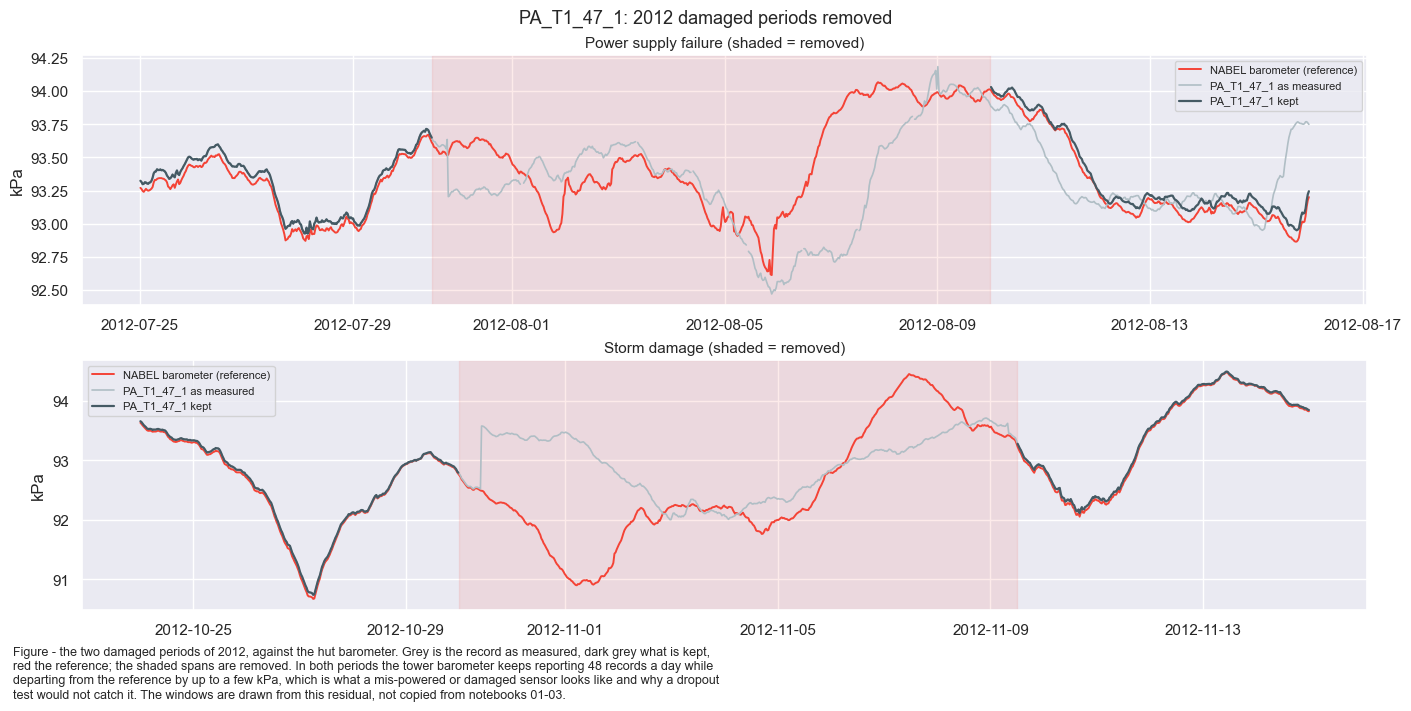

In [20]:
# The two fault periods, before/after, against the reference.
fig, axs = plt.subplots(nrows=2, figsize=(14, 7), dpi=100, layout='constrained')
fig.suptitle(f'{TARGET}: 2012 damaged periods removed', fontsize=13)

for _ax, (_lo, _hi, _label) in zip(axs, [('2012-07-25', '2012-08-15', 'Power supply failure'),
                                         ('2012-10-24', '2012-11-14', 'Storm damage')]):
    _w = slice(_lo, _hi)
    _ax.plot(reference.loc[_w].index, reference.loc[_w].values,
             color='#F44336', lw=1.4, label='NABEL barometer (reference)')
    _ax.plot(_before.loc[_w].index, _before.loc[_w].values,
             color='#B0BEC5', lw=1.2, label=f'{TARGET} as measured')
    _ax.plot(pa_2005_2026[TARGET].loc[_w].index, pa_2005_2026[TARGET].loc[_w].values,
             color='#455A64', lw=1.6, label=f'{TARGET} kept')
    for _s, _e in BAD_WINDOWS_2012:
        if pd.Timestamp(_s) <= pd.Timestamp(_hi) and pd.Timestamp(_e) >= pd.Timestamp(_lo):
            _ax.axvspan(pd.Timestamp(_s), pd.Timestamp(_e), color='#F44336', alpha=.10)
    _ax.set_title(f'{_label} (shaded = removed)', fontsize=11)
    _ax.set_ylabel('kPa')
    _ax.legend(fontsize=8, loc='best')
figcap(fig, "the two damaged periods of 2012, against the hut barometer. Grey is the record as "
            "measured, dark grey what is kept, red the reference; the shaded spans are removed. In "
            "both periods the tower barometer keeps reporting 48 records a day while departing "
            "from the reference by up to a few kPa, which is what a mis-powered or damaged sensor "
            "looks like and why a dropout test would not catch it. The windows are drawn from this "
            "residual, not copied from notebooks 01-03.")

::: {.callout-note title="No zero-offset correction here"}
`01` and `03` remove a nighttime zero-offset because radiation is known to be zero at night.
Pressure has no such reference value, so no equivalent step is applied. Notebook `03`'s trap, a
correction writing into gaps and relabelling fills as measurements, cannot occur here: the clock
shift moves records and the 2012 windows only set `NaN`.
:::

### 🌍 MeteoSwiss Lägern: an independent check across the whole record

Lägern (2.5 km, 845 m) covers the years after NABEL stops in 2018. With a constant altitude offset
removed, tower and Lägern correlate at ~0.99. Lägern (`hPa`, divided by 10) sits about 110 m above
the tower barometer and reads lower; the offset is **fitted from the overlap** (mean of
`tower - Lägern`) and added to Lägern. Diagnostic only. Two checks follow: the alignment guard of
`01`-`03`, which proves the `TIMESTAMP_END -> TIMESTAMP_MID` conversion, and the residual before
and after 2018, where a shift or fault missed after NABEL ended would show.

In [21]:
# Pressure, and also the temperature and vapour pressure of the air column, which the
# barometric check below needs. All three come from the same station and the same file.
_lae = pd.read_parquet(REFPATH)[[REFCOL, REFCOL_TA, REFCOL_VP]].copy()
_lae.index = _lae.index - pd.Timedelta(minutes=15)  # TIMESTAMP_END -> TIMESTAMP_MID
_lae.index.name = pa_2005_2026.index.name
_lae = _lae.reindex(pa_2005_2026.index)
pa_lae = _lae[REFCOL] / 10.0   # hPa -> kPa, onto the product index
ta_lae = _lae[REFCOL_TA]       # deg C
vp_lae = _lae[REFCOL_VP]       # hPa

# Hydrostatic offset, fitted from the overlap rather than guessed: Laegern (845 m) reads lower than
# the tower barometer (~690 m). Add it to Laegern so both sit on the tower's pressure level.
_both = pd.concat([pa_2005_2026[TARGET].rename('tower'), pa_lae.rename('lae')],
                  axis=1, sort=False).dropna()
LAE_OFFSET = float((_both['tower'] - _both['lae']).mean())
lae_adjusted = pa_lae + LAE_OFFSET
print(f"fitted tower - Laegern offset: {LAE_OFFSET:+.4f} kPa "
      f"(mean over {len(_both):,} overlapping records; Laegern reads lower, sitting higher)")

# Alignment guard (as in notebooks 01-03): correlate the measured tower PA against Laegern-adjusted
# at -1/0/+1 half-hour offsets. Offset 0 must win, which proves the TIMESTAMP_MID conversion.
# Pressure is spatially coherent, so the correlation is ~0.99 and the zero-lag peak is clear.
_meas = pa_2005_2026[TARGET]
_scores = {}
for _off in (-1, 0, 1):
    _j = pd.concat([_meas.rename('t'), lae_adjusted.shift(_off).rename('r')],
                   axis=1, sort=False).dropna()
    _scores[_off] = _j['t'].corr(_j['r'])
    print(f"  offset {_off:+d} x 30min: corr {_scores[_off]:.5f}")
assert max(_scores, key=_scores.get) == 0, f"reference is mis-aligned: {_scores}"
print("OK: offset 0 wins, the TIMESTAMP_MID conversion is correct.")

fitted tower - Laegern offset: +1.2745 kPa (mean over 365,179 overlapping records; Laegern reads lower, sitting higher)
  offset -1 x 30min: corr 0.98996
  offset +0 x 30min: corr 0.99026
  offset +1 x 30min: corr 0.98981
OK: offset 0 wins, the TIMESTAMP_MID conversion is correct.


#### 📊 Plot: tower against Lägern, whole record

  while the hut barometer runs     median +0.0765  std 0.0717 kPa  n=221,532
  Laegern the only witness         median -0.1048  std 0.0446 kPa  n=143,648
The scatter is what this check is about, and it is tight in both halves: no timestamp error and no fault went undetected after the hut barometer stopped.
The LEVELS of the two halves differ by 0.181 kPa, which is not scatter. That is the January 2016 step and the slow drift, and the next section takes both of them up.


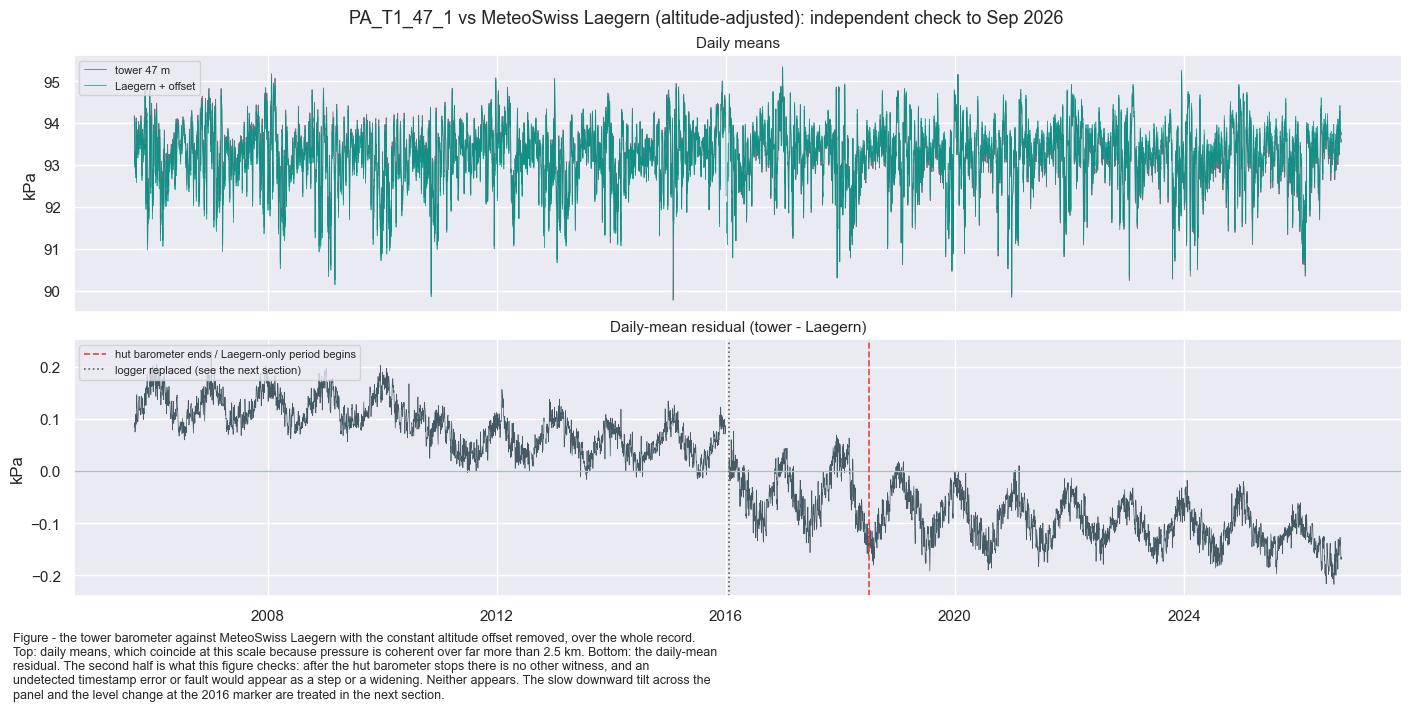

In [22]:
# The post-2018 payoff: NABEL has stopped, Laegern has not. If a timestamp shift or a level fault
# had gone undetected after 2018, the tower - Laegern residual would step or widen there. It does not.
_res_lae = (pa_2005_2026[TARGET] - lae_adjusted)
_split = pa_2005_2026[REFERENCE].last_valid_index()
for _lbl, _sl in [('while the hut barometer runs', slice(None, _split)),
                  ('Laegern the only witness', slice(_split, None))]:
    _r = _res_lae.loc[_sl].dropna()
    print(f"  {_lbl:<32} median {float(_r.median()):+.4f}  std {float(_r.std()):.4f} kPa  n={len(_r):,}")
print("The scatter is what this check is about, and it is tight in both halves: no timestamp "
      "error and no fault went undetected after the hut barometer stopped.")
print("The LEVELS of the two halves differ by "
      f"{abs(float(_res_lae.loc[:_split].median() - _res_lae.loc[_split:].median())):.3f} kPa, "
      "which is not scatter. That is the January 2016 step and the slow drift, and the next "
      "section takes both of them up.")

fig, axs = plt.subplots(nrows=2, figsize=(14, 7), dpi=100, layout='constrained', sharex=True)
fig.suptitle(f'{TARGET} vs MeteoSwiss Laegern (altitude-adjusted): independent check to '
             f'{pa_2005_2026.index[-1]:%b %Y}', fontsize=13)
_daily = pd.DataFrame({'tower': pa_2005_2026[TARGET], 'lae': lae_adjusted}).resample('1D').mean()
axs[0].plot(_daily.index, _daily['tower'].values, lw=0.6, color='#455A64', alpha=.8, label='tower 47 m')
axs[0].plot(_daily.index, _daily['lae'].values, lw=0.6, color='#009688', alpha=.8, label='Laegern + offset')
axs[0].set_ylabel('kPa')
axs[0].set_title('Daily means', fontsize=11)
axs[0].legend(fontsize=8, loc='upper left')

_res_daily = _res_lae.resample('1D').mean()
axs[1].plot(_res_daily.index, _res_daily.values, lw=0.5, color='#455A64')
axs[1].axhline(0, color='#B0BEC5', lw=1)
axs[1].axvline(pa_2005_2026[REFERENCE].last_valid_index(), color='#F44336', ls='--', lw=1.2,
               label='hut barometer ends / Laegern-only period begins')
axs[1].axvline(pd.Timestamp(ACQUISITION_CHANGE), color='#616161', ls=':', lw=1.2,
               label='logger replaced (see the next section)')
axs[1].set_ylabel('kPa')
axs[1].set_title('Daily-mean residual (tower - Laegern)', fontsize=11)
axs[1].legend(fontsize=8, loc='upper left')
figcap(fig, "the tower barometer against MeteoSwiss Laegern with the constant altitude offset "
            "removed, over the whole record. Top: daily means, which coincide at this scale "
            "because pressure is coherent over far more than 2.5 km. Bottom: the daily-mean "
            "residual. The second half is what this figure checks: after the hut barometer stops "
            "there is no other witness, and an undetected timestamp error or fault would appear as "
            "a step or a widening. Neither appears. The slow downward tilt across the panel and "
            "the level change at the 2016 marker are treated in the next section.")

***

## 🔎 Which sensor this is, and what the hardware changes did to it

`PA_T1_47_1` names a variable, not an instrument. This section asks which hardware stands behind
it, what the two boundaries in the record did to it, and whether its absolute level is right, which
for pressure can be checked against physics. It establishes:

1. **one barometer and one conversion**: a Vaisala PTB101B at multiplier `0.184` and offset `600`
   in all seven surviving logger programs;
2. the record **begins long after the last change to this channel**;
3. the **absolute level agrees with the barometric formula**, without a fitted parameter, to within
   a few hundredths of a kPa, including the seasonal shape of the difference;
4. three barometers give three pairwise differences, whose pattern **names the instrument that
   moved**;
5. the **tower barometer steps at the January 2016 acquisition change**, by about 0.09 kPa;
6. **nothing steps at the December 2021 screening splice**;
7. the maintenance record **has never named this barometer** in twenty-one years.

### Helpers for this section

The logger programs and the fieldbook are read, not quoted, so a re-run re-derives the argument.
Both name people, so every string taken from them is redacted as in `01`, `02`, `03` and `08`.

In [23]:
# --- Fieldbook and logger-program redaction ----------------------------------------------------
# The GIN export and the logger programs both name people and this page is public, so every
# string taken from either passes through redact_people() where it is flattened. Same map and rules
# as notebooks 01, 02, 03 and 08; the map lives beside the export, outside this repository.
REDACT_MAP = Path(FIELDBOOK).with_name('redact_names.csv')
ALLOW_LIST = Path(FIELDBOOK).with_name('redact_allow.csv')


def unmapped_report_path(label: str) -> Path:
    """Where the unmapped-name candidates of one audit are written.

    Per label, because this notebook audits two sources: a single shared file would let the
    second audit overwrite the first one's findings.
    """
    _slug = re.sub(r'[^a-z0-9]+', '_', label.lower()).strip('_')
    return Path(FIELDBOOK).with_name(f'redact_unmapped_{_slug}.txt')


def load_redactions(path=None) -> dict:
    """Load the name -> pseudonym map.

    Raises if the map is missing. That is the point: carrying on with redaction quietly disabled
    prints real names into a published page and looks exactly like success.
    """
    path = REDACT_MAP if path is None else Path(path)
    if not path.is_file():
        raise FileNotFoundError(
            f"the redaction map is missing: {path}. Without it the names these files record would "
            f"print unredacted. Restore the file rather than skipping this.")
    tab = pd.read_csv(path, encoding='utf-8')
    missing = {'name', 'pseudonym'}.difference(tab.columns)
    if missing:
        raise ValueError(f"{path}: missing column(s) {sorted(missing)}.")
    pairs = {str(n).strip(): str(p).strip()
             for n, p in zip(tab['name'], tab['pseudonym']) if str(n).strip()}
    if not pairs:
        raise ValueError(f"{path}: holds no usable name -> pseudonym pairs.")
    return pairs


REDACTIONS = load_redactions()
# Longest surface form first, so a bare surname cannot corrupt a double-barrelled one that starts
# with it. Lookarounds rather than \b, because some forms end in an initial.
_REDACT_RX = re.compile(r'(?<!\w)(' + '|'.join(re.escape(n) for n in
                                               sorted(REDACTIONS, key=len, reverse=True))
                        + r')(?!\w)')


def redact_people(s) -> str:
    """Replace every mapped name with its stable pseudonym."""
    return _REDACT_RX.sub(lambda m: REDACTIONS[m.group(1)], str(s))


def strip_html(text) -> str:
    """Flatten one GIN fieldbook entry to plain text, with the people it names redacted."""
    flat = html.unescape(re.sub(r'<[^>]+>', ' ', str(text)))
    return redact_people(re.sub(r'\s+', ' ', flat).strip())


_NAME_TOKEN = r"[A-ZÄÖÜ][\wÄÖÜäöüß'-]{1,20}"
_NAME_UNIT = _NAME_TOKEN + r'(?:\s+' + _NAME_TOKEN + r'){0,2}'
_NAME_SHAPES = (
    re.compile(r'\((' + _NAME_UNIT + r'(?:\s*[,+&]\s*' + _NAME_UNIT + r')*)\s*'
               r'(?:\d{1,2}\.\d{1,2}\.\d{4})?\)'),
    re.compile(r'(?:with|by|durch|von|gemaess)\s+(' + _NAME_TOKEN + r'(?:\s+' + _NAME_TOKEN + r')?)'),
)


def audit_unmapped_names(texts, label='fieldbook', write_report: bool = True) -> int:
    """Raise if any name-shaped token survived redaction.

    A newer export can name someone the map has never seen. Candidates are never printed - an
    exception message is stored in a notebook like any other output - so they go to a file beside
    the map and only the count is shown.
    """
    allow = set(pd.read_csv(ALLOW_LIST, encoding='utf-8')['term'].astype(str).str.strip())
    found = {}
    for _t in texts:
        for _rx in _NAME_SHAPES:
            for _m in _rx.finditer(str(_t)):
                for _tok in re.findall(_NAME_TOKEN, _m.group(1)):
                    if _tok.isupper() or any(ch.isdigit() for ch in _tok) or _tok in allow:
                        continue
                    found[_tok] = found.get(_tok, 0) + 1
    if found:
        _report = unmapped_report_path(label)
        if write_report:
            _report.write_text(
                '\n'.join(f'{n}\t{t}' for t, n in sorted(found.items(), key=lambda kv: -kv[1])),
                encoding='utf-8')
        raise ValueError(
            f"{label}: {len(found)} name-shaped token(s) survived redaction. They are deliberately "
            f"NOT shown here - see {_report}. Add the people to redact_names.csv and the "
            f"technical terms to redact_allow.csv, then re-run.")
    print(f"  {label}: no unmapped name-shaped tokens ({len(allow)} allowlisted terms)")
    return 0


def program_excerpt(path, pattern: str, before: int = 6, after: int = 4, expect: int = 1) -> str:
    """The lines of a logger program around `pattern`, redacted.

    Only the matched instruction is returned, never the file header: these programs are signed by
    their authors. Raises unless the pattern matches exactly `expect` times. Both directions
    matter: no match reads as 'the program does not measure this', and an over-broad pattern
    quietly prints the wrong instruction next to the argument it is supposed to support.
    """
    lines = Path(path).read_text(encoding='latin-1').splitlines()
    blocks = []
    for i, line in enumerate(lines):
        if re.search(pattern, line):
            lo, hi = max(0, i - before), min(len(lines), i + after + 1)
            blocks.append('\n'.join(lines[lo:hi]))
    if len(blocks) != expect:
        raise ValueError(f"{Path(path).name}: {pattern!r} matched {len(blocks)} time(s), expected "
                         f"{expect}. The program layout has changed, the wrong file is configured, "
                         f"or the pattern is not specific enough.")
    return redact_people('\n\n'.join(blocks))


def uncommented(excerpt: str) -> str:
    """Drop the comment part of every line of a logger-program excerpt.

    Notebook 03 did not need this and this notebook does. Both program languages keep dead code in
    comments, and the CR1000 keeps some here: two lines above the live pressure instruction sits a
    commented-out single-ended version of it, carrying a DIFFERENT multiplier. A parser reading the
    raw excerpt finds that one first and reports constants the logger has never applied. CR10X
    comments begin with `;`, CRBasic comments with `'`.
    """
    out = []
    for line in excerpt.splitlines():
        stripped = re.split(r"[;']", line, maxsplit=1)[0].rstrip()
        if stripped.strip():
            out.append(stripped)
    return '\n'.join(out)


def calibration_constants(excerpt: str, consts: dict | None = None) -> dict:
    """The multiplier and offset of one measurement instruction, parsed from its own text.

    Two shapes occur across the two program languages and both are matched on their own terms: the
    CR10X lists the two numbers as numbered parameters, while the CR1000 passes them as the last
    two arguments of a `VoltSe(...)` or `VoltDiff(...)` call. Copied from notebook 03, including
    the `consts` path, which this variable does not use - the CR1000 writes its pressure constants
    as literals.

    Raises if either number cannot be found. A silently empty result would make the comparison
    below pass by having nothing to disagree about.
    """
    if 'Mult' in excerpt:                                    # CR10X parameter listing
        _m = re.search(r'^\s*\d+:\s*([\d.]+)\s+Mult', excerpt, re.M)
        _o = re.search(r'^\s*\d+:\s*([\d.]+)\s+Offset', excerpt, re.M)
        tokens = [_m.group(1) if _m else None, _o.group(1) if _o else None]
    else:                                                    # CR1000 VoltSe/VoltDiff call
        _call = re.search(r'Volt(?:Se|Diff)\s*\(([^)]*)\)', excerpt)
        _args = [a.strip() for a in _call.group(1).split(',')] if _call else []
        tokens = _args[-2:] if len(_args) >= 2 else [None, None]

    values = []
    for _tok in tokens:
        if _tok is None:
            raise ValueError("could not parse a multiplier and an offset from the instruction - "
                             "the program language or the layout has changed")
        try:
            values.append(float(_tok))
        except ValueError:
            if not consts or _tok not in consts:
                raise ValueError(
                    f"the instruction gives its constant as the name {_tok!r}, which is not among "
                    f"the declarations passed in.")
            values.append(consts[_tok])
    return {'multiplier': values[0], 'offset': values[1]}

In [24]:
# The guards guard. A helper that silently returns nothing is worse than no helper, so every
# failure path is exercised before anything is read.
try:
    program_excerpt(PROGRAM_AFTER, r'ThisPatternIsNotInAnyLoggerProgram')
except ValueError as _exc:
    print(f"OK, program_excerpt raised on a pattern that does not occur: {_exc}")
else:
    raise AssertionError("(!) program_excerpt accepted a pattern that does not occur.")

# 'Ada Lovelace' is nobody at this site, so the control can spell her out without disclosing
# anything - and it writes no report, so the real one is not overwritten by a test.
try:
    audit_unmapped_names(['12.05.2019 (Ada Lovelace) replaced the logger battery'],
                         'positive control', write_report=False)
except ValueError:
    print("OK, the unknown-name net fired on a name that is not in the map")
else:
    raise AssertionError("(!) the unknown-name net did not fire on an unmapped name.")

# The constant parser must refuse an instruction it cannot read at all.
try:
    calibration_constants("18:  Volt (Diff) (P2) ;Messung von Kin\n 1: 1        Reps")
except ValueError as _exc:
    print(f"OK, calibration_constants raised on an instruction with no constants: {_exc}")
else:
    raise AssertionError("(!) calibration_constants accepted an instruction carrying no constants.")

# And the comment stripper must actually remove something here, or the constants reported below
# would be the ones in the dead line rather than the ones the logger applies.
_probe = "    'VoltSe (X,1,mV2500,13,1,0,_50Hz,0.1,0)\n    VoltDiff (X,1,mV2500,7,True,0,_50Hz,0.184,600)"
assert calibration_constants(_probe) != calibration_constants(uncommented(_probe)), \
    "(!) the comment stripper changes nothing, so a commented-out instruction could be reported"
print(f"OK, uncommented() changes the answer: raw {calibration_constants(_probe)} -> "
      f"live {calibration_constants(uncommented(_probe))}")

OK, program_excerpt raised on a pattern that does not occur: CH-LAE_iDL_T1_47_1.CR1: 'ThisPatternIsNotInAnyLoggerProgram' matched 0 time(s), expected 1. The program layout has changed, the wrong file is configured, or the pattern is not specific enough.
OK, the unknown-name net fired on a name that is not in the map
OK, calibration_constants raised on an instruction with no constants: could not parse a multiplier and an offset from the instruction - the program language or the layout has changed
OK, uncommented() changes the answer: raw {'multiplier': 0.1, 'offset': 0.0} -> live {'multiplier': 0.184, 'offset': 600.0}


### 1️⃣ One barometer, one conversion, seven programs

The CR1000 program names the instrument and converts its signal on the next line; the six CR10X
programs (2004-2006) write the same two numbers in their own language, into storage location 40.
All seven are parsed and asserted to agree. A multiplier change at the 2016 changeover would make
the series step there by construction.

#### 📋 Table: calibration constants per logger program

In [25]:
# The CR1000 instruction. The excerpt deliberately shows the two comment lines above it: the
# first names the instrument, the second is a commented-out single-ended version of the same
# measurement at a different multiplier, which is why uncommented() exists.
_ex_cr1000 = program_excerpt(PROGRAM_AFTER, r'Vaisala PTB101B', before=0, after=3)
print(_ex_cr1000)

CONSTANTS = {Path(PROGRAM_AFTER).name: calibration_constants(uncommented(_ex_cr1000))}
_cr10x_excerpts = []
for _p in PROGRAMS_CR10X:
    _ex = program_excerpt(_p, r'^; Pressure sensor', before=0, after=13)
    _cr10x_excerpts.append(_ex)
    CONSTANTS[Path(_p).name] = calibration_constants(uncommented(_ex))

print(f"\n--- {Path(PROGRAMS_CR10X[0]).name}, the oldest surviving program")
print(_cr10x_excerpts[0])
audit_unmapped_names(_cr10x_excerpts + [_ex_cr1000], 'logger programs')

tabcap("the conversion every surviving logger program applies to the tower pressure channel, "
       "oldest first. The two program languages write the same two numbers differently and each "
       "shape is matched on its own terms. The 2016 changeover changes the measurement mode and "
       "the stored unit, not the calibration")
_prog = pd.DataFrame(CONSTANTS).T.reindex(
    [Path(_p).name for _p in PROGRAMS_CR10X] + [Path(PROGRAM_AFTER).name])
_prog.index.name = 'logger program'
_prog['logger'] = ['CR10X'] * len(PROGRAMS_CR10X) + ['CR1000']
_prog['measurement'] = (['Excite-Delay (SE), 2500 mV excitation'] * len(PROGRAMS_CR10X)
                        + ['VoltDiff, differential'])
_prog['stored as'] = ['hPa'] * len(PROGRAMS_CR10X) + ['Pa (x100 on the following line)']
display(_prog)

# One conversion across every program that measures this sensor, CR10X and CR1000 alike.
_mults = {v['multiplier'] for v in CONSTANTS.values()}
_offsets = {v['offset'] for v in CONSTANTS.values()}
print(f"\ndistinct multipliers over the {len(CONSTANTS)} programs: {sorted(_mults)}")
print(f"distinct offsets: {sorted(_offsets)}")
assert _mults == {0.184} and _offsets == {600.0}, (
    "the programs no longer all apply the same conversion to the pressure channel - the argument "
    "that the 2016 changeover cannot have rescaled this series no longer holds")

# The two numbers are not arbitrary: they are the sensor's own range written as a straight line
# over the logger's 2500 mV input, which is what identifies the instrument.
MULTIPLIER, OFFSET_HPA = sorted(_mults)[0], sorted(_offsets)[0]
_span = (OFFSET_HPA, MULTIPLIER * 2500 + OFFSET_HPA)
print(f"conversion span: {_span[0]:.0f} .. {_span[1]:.0f} hPa over 0 .. 2500 mV")
assert _span == (600.0, 1060.0), (
    "the conversion no longer spans 600-1060 hPa, which is the range of the barometer the CR1000 "
    "program names - the identification of the instrument must be re-derived")
print("This is the range of the Vaisala PTB101B the CR1000 program names, so the same barometer "
      "stands behind both acquisition systems.")

    'Vaisala PTB101B barometric sensor
    'VoltSe (PA_T1_47_1,1,mV2500,13,1,0,_50Hz,0.1,0)
    VoltDiff (PA_T1_47_1,1,mV2500,7,True,0,_50Hz,0.184,600)
    PA_T1_47_1 = PA_T1_47_1 * 100 'pressure in Pa

--- LAEGEREN.20040526.CSI, the oldest surviving program
; Pressure sensor
;----------------


3:  Excite-Delay (SE) (P4)
 1: 1        Reps
 2: 05       2500 mV Slow Range
 3: 1        SE Channel
 4: 1        Excite all reps w/Exchan 1
 5: 100      Delay (0.01 sec units)
 6: 2500     mV Excitation
 7: 40       Loc [ Pressure  ]
 8: 0.184    Mult
 9: 600      Offset
  logger programs: no unmapped name-shaped tokens (58 allowlisted terms)
Table - the conversion every surviving logger program applies to the tower pressure channel, oldest
first. The two program languages write the same two numbers differently and each shape is matched on
its own terms. The 2016 changeover changes the measurement mode and the stored unit, not the
calibration



,multiplier,offset,logger,measurement,stored as
logger program,,,,,
LAEGEREN.20040526.CSI,0.184,600.0,CR10X,"Excite-Delay (SE), 2500 mV excitation",hPa
LAEGEREN.20040810.CSI,0.184,600.0,CR10X,"Excite-Delay (SE), 2500 mV excitation",hPa
LAEGEREN.20041228.CSI,0.184,600.0,CR10X,"Excite-Delay (SE), 2500 mV excitation",hPa
LAEGEREN.20050818.CSI,0.184,600.0,CR10X,"Excite-Delay (SE), 2500 mV excitation",hPa
LAEGEREN.20050914.CSI,0.184,600.0,CR10X,"Excite-Delay (SE), 2500 mV excitation",hPa
LAEGEREN.20060524.csi,0.184,600.0,CR10X,"Excite-Delay (SE), 2500 mV excitation",hPa
CH-LAE_iDL_T1_47_1.CR1,0.184,600.0,CR1000,"VoltDiff, differential",Pa (x100 on the following line)



distinct multipliers over the 7 programs: [0.184]
distinct offsets: [600.0]
conversion span: 600 .. 1060 hPa over 0 .. 2500 mV
This is the range of the Vaisala PTB101B the CR1000 program names, so the same barometer stands behind both acquisition systems.


The 2016 changeover did change the reading, not the calibration. The CR10X excited the sensor and
measured it **single-ended**, the CR1000 **differentially**, and the CR1000 multiplies by 100 on the next line:
the unit break comes from the logger program, not the database. A single-ended measurement carries
any ground offset between sensor and logger and a differential one does not, so the level could
move with the calibration unchanged. Step 5️⃣ finds that it did.

### 2️⃣ The record begins long after the last change to this channel

The last pressure entry in the CR10X header history is dated **31 March 2004**; the record begins in
September 2005. Unlike `PPFD_IN`, whose location held another probe until August 2004, this column
has never held anything else.

In [26]:
# The dated history line, taken from the programs rather than quoted. before=0/after=0 returns
# the single line, so nothing of the signed header comes with it.
_hist = {Path(_p).name: program_excerpt(_p, r'changed pressure variable to high resolution',
                                        before=0, after=0).strip().lstrip('; ')
         for _p in PROGRAMS_CR10X}
assert len(set(_hist.values())) == 1, "the programs no longer agree on the pressure history line"
CHANNEL_CHANGE = pd.Timestamp(re.match(r'(\d{2})\.(\d{2})\.(\d{4})',
                                       next(iter(_hist.values()))).expand(r'\3-\2-\1'))
print(f"history line, identical in all {len(_hist)} CR10X programs:")
print(f"  {next(iter(_hist.values()))}")

FIRST_MEASURED = pa_2005_2026[TARGET].first_valid_index()
print(f"\nlast change to the pressure channel: {CHANNEL_CHANGE:%d %b %Y}")
print(f"first measured {TARGET} record:      {FIRST_MEASURED:%d %b %Y %H:%M}")
print(f"difference: {(FIRST_MEASURED.normalize() - CHANNEL_CHANGE).days:,} days")
assert FIRST_MEASURED > CHANNEL_CHANGE, (
    "the record now begins before the last change to this channel, so its earliest values were "
    "converted differently and the column spans two conversions")
print("\nThe record starts where the archive starts, not where the sensor starts: the barometer "
      "was already being logged when the oldest surviving program was written in May 2004.")

history line, identical in all 6 CR10X programs:
  31.03.2004 changed pressure variable to high resolution

last change to the pressure channel: 31 Mar 2004
first measured PA_T1_47_1 record:      02 Sep 2005 10:15
difference: 520 days

The record starts where the archive starts, not where the sensor starts: the barometer was already being logged when the oldest surviving program was written in May 2004.


### 3️⃣ The absolute level, against the barometric formula

Pressure falls with height by a law with no free parameter, so a barometer's elevation can be read
back from its readings: an **absolute** test that a unit or offset error fails by orders of
magnitude. The scale height uses the **virtual** temperature of the column (humid air is lighter; ignoring
this overstates the predicted difference)
from Lägern's temperature and vapour pressure, with the layer mean half a lapse rate below the
station. The test covers the level and the seasonal shape of the difference, which follows
temperature; a formula right about the mean by accident will not also match the cycle.

#### 📋 Table: barometer elevation from the barometric formula

In [27]:
# Constants of the hypsometric equation. None of them is fitted.
G_ACCEL = 9.80665     # m s-2
R_DRY = 287.05        # J kg-1 K-1, specific gas constant of dry air
LAPSE_RATE = 0.0065   # K m-1, standard atmosphere; used only to put the layer mean temperature
                      # between the two sensors rather than at the upper one
NOMINAL_ELEVATION = SITE_BASE_ELEVATION + SENSOR_HEIGHT
KPA_PER_METRE = 93.3 / (R_DRY * 283.0 / G_ACCEL)   # for reporting a pressure as metres of air


def scale_height(t_degc, vp_hpa, p_kpa, dz):
    """Scale height R*Tv/g of the layer, from the reference station's own temperature and humidity."""
    t_layer = t_degc + 273.15 + LAPSE_RATE * dz / 2
    return R_DRY * (t_layer / (1 - 0.378 * vp_hpa / (p_kpa * 10))) / G_ACCEL


def predicted_pressure(p_ref_kpa, t_ref_degc, vp_ref_hpa, dz):
    """Pressure `dz` metres below a station, from that station's own pressure, temperature and humidity."""
    return p_ref_kpa * np.exp(dz / scale_height(t_ref_degc, vp_ref_hpa, p_ref_kpa, dz))


def implied_elevation(here: pd.Series, there: pd.Series, elevation_there: float,
                      t_there: pd.Series, vp_there: pd.Series,
                      min_records: int = 10_000) -> dict:
    """Where the hypsometric equation puts `here`'s barometer, given a station of known elevation.

    Raises if either series is not plausible surface pressure in kPa, or if too few records
    overlap. The unit guard is the point of the helper as much as the answer is: run on a series
    still stored in Pa this has to stop, not return a number.
    """
    both = pd.concat([here.rename('p'), there.rename('pref'), t_there.rename('t'),
                      vp_there.rename('e')], axis=1, sort=False).dropna()
    if len(both) < min_records:
        raise ValueError(f"only {len(both):,} overlapping records, too few for a level check "
                         f"(at least {min_records:,} are wanted).")
    _lo, _hi = PA_PLAUSIBLE_KPA
    for _name, _s in (('the series under test', both['p']), ('the reference', both['pref'])):
        if not (_lo <= float(_s.mean()) <= _hi):
            raise ValueError(f"{_name} has mean {float(_s.mean()):,.2f}, which is not surface "
                             f"pressure in kPa ({_lo}-{_hi}). Convert before comparing levels.")
    _p, _pref = float(both['p'].mean()), float(both['pref'].mean())
    _dz = 0.0
    for _ in range(3):   # the layer mean temperature depends on dz, which depends on it
        _h = scale_height(float(both['t'].mean()), float(both['e'].mean()), _pref, _dz)
        _dz = -_h * np.log(_p / _pref)
    return {'n': len(both), 'measured difference (kPa)': _p - _pref,
            'scale height (m)': _h, 'implied elevation (m)': elevation_there + _dz}


# Two independent references, one about 110 m above the barometer and one 45 m below it.
_levels = {
    f'MeteoSwiss Lägern, {LAE_ELEVATION:.0f} m': implied_elevation(
        pa_2005_2026[TARGET], pa_lae, LAE_ELEVATION, ta_lae, vp_lae),
    f'NABEL hut, {SITE_BASE_ELEVATION + HUT_HEIGHT:.0f} m': implied_elevation(
        pa_2005_2026[TARGET], pa_2005_2026[REFERENCE], SITE_BASE_ELEVATION + HUT_HEIGHT,
        ta_lae, vp_lae),
}
tabcap(f"where the barometric formula puts the tower barometer, from each reference in turn. The "
       f"nominal elevation is the tower base at {SITE_BASE_ELEVATION:.0f} m plus the "
       f"{SENSOR_HEIGHT:.0f} m in the field name; nothing in the calculation is fitted")
level_table = pd.DataFrame(_levels).T
level_table['nominal (m)'] = NOMINAL_ELEVATION
level_table['departure (m)'] = level_table['implied elevation (m)'] - NOMINAL_ELEVATION
display(level_table.round(2))

# Tolerance from what the record does, not a round number. The two references disagree by up to
# 0.07 kPa (step 4), about 6 m of air, and the barometer's exact height in its enclosure is not
# documented. 30 m is above both and well below the 47 m between tower base and top, so the check
# still fails if the field name is wrong about which of the two the sensor sits at.
ELEVATION_TOLERANCE_M = 30.0
for _label, _row in level_table.iterrows():
    print(f"  {_label:<28} -> {_row['implied elevation (m)']:.0f} m "
          f"({_row['departure (m)']:+.0f} m from nominal, "
          f"from a difference of {_row['measured difference (kPa)']:+.3f} kPa)")
    assert abs(_row['departure (m)']) < ELEVATION_TOLERANCE_M, (
        f"{_label}: the barometric formula puts this barometer {_row['departure (m)']:+.0f} m from "
        f"where it hangs, past the {ELEVATION_TOLERANCE_M:.0f} m this check allows. Either the "
        f"level of the series is wrong or the geometry in the settings is")
    assert _row['implied elevation (m)'] > SITE_BASE_ELEVATION + SENSOR_HEIGHT / 2, (
        f"{_label}: the implied elevation is nearer the tower base than the tower top, which "
        f"contradicts the 47 m in the field name")
print(f"\nBoth references put the barometer within {ELEVATION_TOLERANCE_M:.0f} m of where it "
      f"hangs, and they agree with each other to "
      f"{abs(level_table['implied elevation (m)'].diff().iloc[-1]):.0f} m. The absolute level of "
      f"the exported series is right.")

Table - where the barometric formula puts the tower barometer, from each reference in turn. The
nominal elevation is the tower base at 689 m plus the 47 m in the field name; nothing in the
calculation is fitted



,n,measured difference (kPa),scale height (m),implied elevation (m),nominal (m),departure (m)
"MeteoSwiss Lägern, 845 m",365002.0,1.27,8263.96,731.25,736.0,-4.75
"NABEL hut, 691 m",221203.0,-0.41,8260.59,727.19,736.0,-8.81


  MeteoSwiss Lägern, 845 m     -> 731 m (-5 m from nominal, from a difference of +1.274 kPa)
  NABEL hut, 691 m             -> 727 m (-9 m from nominal, from a difference of -0.409 kPa)

Both references put the barometer within 30 m of where it hangs, and they agree with each other to 4 m. The absolute level of the exported series is right.


In [28]:
# The guards guard. This check exists to catch a level error, so it has to fail on one: run on
# the diive source in its stored unit, which is off by exactly the factor this notebook harmonises
# away, it must stop rather than report an elevation.
try:
    implied_elevation(diive_pa[TARGET].reindex(pa_2005_2026.index), pa_lae, LAE_ELEVATION,
                      ta_lae, vp_lae)
except ValueError as _exc:
    print(f"OK, the level check raised on a series still stored in Pa: {_exc}")
else:
    raise AssertionError("(!) the level check accepted a series that is off by a factor of 1000.")

try:
    # The last two days of the record, far below min_records.
    implied_elevation(pa_2005_2026[TARGET].loc[pd.Timestamp(PERIOD_END) - pd.Timedelta(days=2):],
                      pa_lae, LAE_ELEVATION, ta_lae, vp_lae)
except ValueError as _exc:
    print(f"OK, the level check raised on too few records: {_exc}")
else:
    raise AssertionError("(!) the level check accepted a handful of records.")

OK, the level check raised on a series still stored in Pa: the series under test has mean 93,163.68, which is not surface pressure in kPa (85.0-100.0). Convert before comparing levels.
OK, the level check raised on too few records: only 97 overlapping records, too few for a level check (at least 10,000 are wanted).


#### 📊 Plot: tower minus Lägern, measured and predicted

seasonal amplitude: measured 0.089 kPa, predicted 0.079 kPa
correlation of the two annual cycles: 0.9797


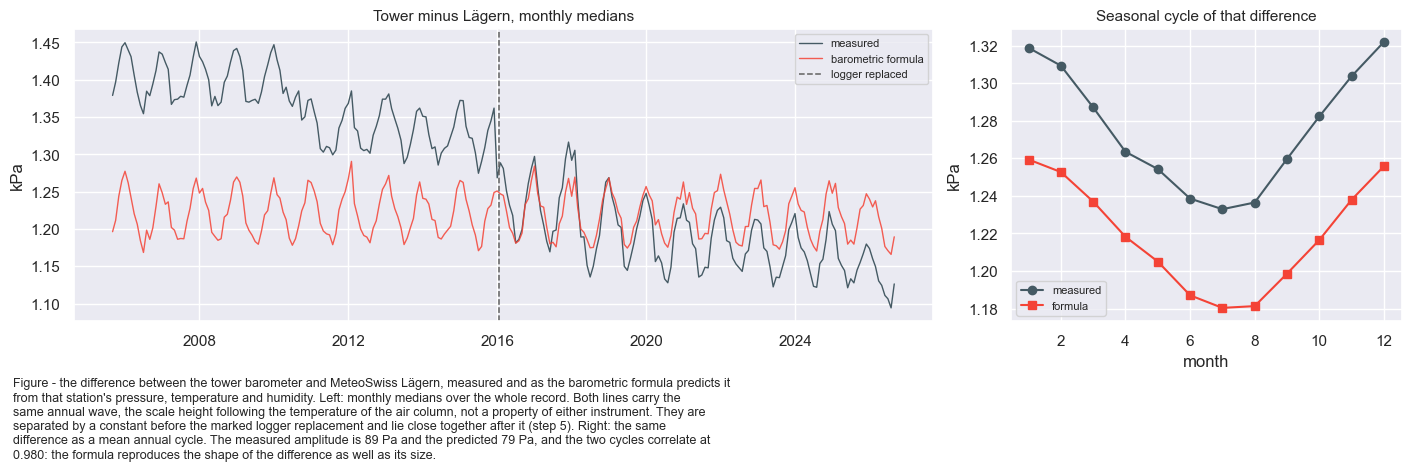

In [29]:
# The shape, not only the level. The prediction is computed per half-hour from the reference
# station's own pressure, temperature and humidity, and compared as monthly medians.
_pred_lae = predicted_pressure(pa_lae, ta_lae, vp_lae, LAE_ELEVATION - NOMINAL_ELEVATION)
_shape = pd.DataFrame({'measured': pa_2005_2026[TARGET] - pa_lae,
                       'predicted': _pred_lae - pa_lae}).resample('MS').median().dropna()
_clim = _shape.groupby(_shape.index.month).mean()

fig, axs = plt.subplots(ncols=2, figsize=(14, 4.6), dpi=100, layout='constrained',
                        width_ratios=[2.2, 1])
axs[0].plot(_shape.index, _shape['measured'], lw=1.0, color='#455A64', label='measured')
axs[0].plot(_shape.index, _shape['predicted'], lw=1.0, color='#F44336', alpha=.85,
            label='barometric formula')
axs[0].axvline(pd.Timestamp(ACQUISITION_CHANGE), color='#616161', ls='--', lw=1.1,
               label='logger replaced')
axs[0].set_ylabel('kPa')
axs[0].set_title('Tower minus Lägern, monthly medians', fontsize=11)
axs[0].legend(fontsize=8)
axs[1].plot(_clim.index, _clim['measured'], marker='o', color='#455A64', label='measured')
axs[1].plot(_clim.index, _clim['predicted'], marker='s', color='#F44336', label='formula')
axs[1].set_xlabel('month')
axs[1].set_ylabel('kPa')
axs[1].set_title('Seasonal cycle of that difference', fontsize=11)
axs[1].legend(fontsize=8)

_amp = (float(_clim['measured'].max() - _clim['measured'].min()),
        float(_clim['predicted'].max() - _clim['predicted'].min()))
_corr = float(_clim['measured'].corr(_clim['predicted']))
figcap(fig, f"the difference between the tower barometer and MeteoSwiss Lägern, measured and as the "
            f"barometric formula predicts it from that station's pressure, temperature and "
            f"humidity. Left: monthly medians over the whole record. Both lines carry the same "
            f"annual wave, the scale height following the temperature of the air column, not a "
            f"property of either instrument. They are separated before the marked logger "
            f"replacement, lie close together just after it and draw apart steadily from about "
            f"2019, the drift described in step 5. Right: the same "
            f"difference as a mean annual cycle. The measured amplitude is {_amp[0] * 1000:.0f} Pa "
            f"and the predicted {_amp[1] * 1000:.0f} Pa, and the two cycles correlate at "
            f"{_corr:.3f}: the formula reproduces the shape of the difference as well as its size.")

print(f"seasonal amplitude: measured {_amp[0]:.3f} kPa, predicted {_amp[1]:.3f} kPa")
print(f"correlation of the two annual cycles: {_corr:.4f}")
assert _corr > 0.9, (
    "the measured seasonal cycle of the tower-Laegern difference no longer follows the one the "
    "barometric formula predicts, so the agreement in the level above may be a coincidence")

### 4️⃣ Three barometers, and the pattern that names the one that moved

Each barometer appears in two of the three pairwise differences, so a change at one moves exactly
its own two and leaves the third alone (the argument of notebook `02` and
`RADIATION_SENSOR_CONTINUITY.ipynb`). Pressure errors are **additive**: differences, not ratios.

The differences carry a physical seasonal cycle of about 0.09 kPa (step 3️⃣), so monthly medians
are averaged over calendar months and a year missing a month is dropped. This drops 2026, which
ends in September; the yearly statistics stop at `LAST_FULL_YEAR`. Changes are read year on year,
against what the same instruments do in an ordinary year.

#### 📋 Table: pairwise differences by year

In [30]:
TOWER, HUT, LAEGERN = 'tower 47 m', 'NABEL hut 2 m', 'MeteoSwiss Lägern'
BAROMETERS = {TOWER: pa_2005_2026[TARGET], HUT: pa_2005_2026[REFERENCE], LAEGERN: pa_lae}
PAIRS = [(TOWER, LAEGERN), (TOWER, HUT), (HUT, LAEGERN)]


def difference_by_year(a: str, b: str, min_records: int = 200) -> pd.Series:
    """Month-matched yearly mean of `a` - `b`, in kPa.

    Monthly medians first, then the mean over calendar months; a year not covering all twelve is
    dropped rather than compared against one that does, and nothing after LAST_FULL_YEAR enters.
    Raises rather than returning a thin
    result: a difference built from a handful of half-hours reads exactly like one built from
    thousands.
    """
    _d = (BAROMETERS[a] - BAROMETERS[b]).dropna()
    _m = _d.groupby([_d.index.year, _d.index.month]).median()
    _m.index.names = ['year', 'month']
    _m = _m[_d.groupby([_d.index.year, _d.index.month]).count() >= min_records]
    if _m.empty:
        raise ValueError(f"{a} - {b}: no calendar month reaches {min_records} records")
    _months = _m.groupby(level=0).count()
    # The twelve-month rule already drops the partial 2026; the cut at LAST_FULL_YEAR states it.
    return _m.groupby(level=0).mean()[_months == 12].loc[:LAST_FULL_YEAR]


DIFFS = {_pair: difference_by_year(*_pair) for _pair in PAIRS}
diff_table = pd.DataFrame({f'{a} - {b}': _s for (a, b), _s in DIFFS.items()})
diff_table.index.name = 'YEAR'
change = diff_table.diff()
DECIDABLE = [int(_y) for _y in diff_table.index if diff_table.loc[_y].notna().all()
             and _y - 1 in diff_table.index and diff_table.loc[_y - 1].notna().all()]
print(f"years in which all three differences exist and can be compared with the year before: "
      f"{DECIDABLE[0]}-{DECIDABLE[-1]}")


def moved(changes: dict, threshold: float):
    """Which barometer a set of pairwise changes identifies, or None.

    Returns None when the pattern does not identify one - two instruments moving at once looks
    exactly like a row with several large entries, and a rule that guessed in that case would be
    worse than no rule. A difference says two barometers separated, never which of them left.
    """
    _big = {_p for _p, _v in changes.items() if pd.notna(_v) and abs(_v) >= threshold}
    if not _big:
        return None
    for _b in BAROMETERS:
        _own = {_p for _p in changes if _b in _p}
        if _big == _own:
            return _b
    return None


# The threshold is taken from what these three instruments do in an ordinary year rather than
# chosen round: a wall set below the year-to-year scatter would fire on nothing having happened.
EVENT_THRESHOLD = 0.04   # kPa
_typical = change.loc[DECIDABLE].abs().median()
assert EVENT_THRESHOLD > 2 * float(_typical.max()), (
    "the event threshold has fallen to within a factor of two of the ordinary year-to-year "
    "scatter of these differences, which would make it fire on ordinary weather and screening")

ATTRIBUTED = {_y: moved({_p: change.loc[_y, f'{_p[0]} - {_p[1]}'] for _p in PAIRS},
                        EVENT_THRESHOLD) for _y in DECIDABLE}

tabcap(f"each pairwise difference between the three barometers, year by year, in kPa, for full "
       f"years to {LAST_FULL_YEAR}. Monthly medians averaged over calendar months, so neither the "
       f"season nor a year's gaps can move a row. All three instruments saw the same weather, so a "
       f"row is not a statement about the weather")
display(diff_table.round(4))

years in which all three differences exist and can be compared with the year before: 2007-2017
Table - each pairwise difference between the three barometers, year by year, in kPa, for full years
to 2025. Monthly medians averaged over calendar months, so neither the season nor a year's gaps can
move a row. All three instruments saw the same weather, so a row is not a statement about the
weather



,tower 47 m - MeteoSwiss Lägern,tower 47 m - NABEL hut 2 m,NABEL hut 2 m - MeteoSwiss Lägern
YEAR,,,
2006,1.4031,-0.4034,1.8056
2007,1.4017,-0.4234,1.8246
2008,1.4010,-0.4271,1.8287
2009,1.3988,-0.4058,1.8046
2010,1.3853,-0.3966,1.7812
2011,1.3293,-0.3805,1.7104
2012,1.3359,-0.3690,1.7053
2013,1.3390,-0.3633,1.7026
2014,1.3226,-0.3651,1.6886


#### 📋 Table: change from the previous year

In [31]:
tabcap(f"the change in each difference from the previous year, and the barometer the pattern "
       f"identifies. A change at one barometer moves the two differences it appears in and no "
       f"other; where the pattern does not point at a single instrument the rule returns nothing. "
       f"Threshold {EVENT_THRESHOLD} kPa, against a typical year-to-year change of "
       f"{float(_typical.max()):.4f} kPa")
scan = change.loc[DECIDABLE].copy()
scan['identifies'] = [ATTRIBUTED[_y] or '' for _y in DECIDABLE]
display(scan.round(4))

_unattributed = [_y for _y in DECIDABLE if ATTRIBUTED[_y] is None]
_worst_quiet = float(change.loc[_unattributed].abs().max().max())
print(f"\nlargest change in any year the rule attributes to nobody: {_worst_quiet:.4f} kPa")
assert EVENT_THRESHOLD > _worst_quiet, (
    "a year the attribution rule cannot explain now carries a change larger than the event "
    "threshold, so either two instruments moved together or the threshold is wrong")
for _y, _who in ATTRIBUTED.items():
    if _who:
        print(f"  {_y}: {_who}")

Table - the change in each difference from the previous year, and the barometer the pattern
identifies. A change at one barometer moves the two differences it appears in and no other; where
the pattern does not point at a single instrument the rule returns nothing. Threshold 0.04 kPa,
against a typical year-to-year change of 0.0140 kPa



,tower 47 m - MeteoSwiss Lägern,tower 47 m - NABEL hut 2 m,NABEL hut 2 m - MeteoSwiss Lägern,identifies
YEAR,,,,
2007,-0.0014,-0.0200,0.0190,
2008,-0.0007,-0.0037,0.0041,
2009,-0.0022,0.0213,-0.0241,
2010,-0.0134,0.0092,-0.0234,
2011,-0.0561,0.0160,-0.0708,MeteoSwiss Lägern
2012,0.0067,0.0115,-0.0051,
2013,0.0031,0.0057,-0.0027,
2014,-0.0164,-0.0018,-0.0140,
2015,0.0059,0.0034,0.0023,



largest change in any year the rule attributes to nobody: 0.0241 kPa
  2011: MeteoSwiss Lägern
  2016: tower 47 m
  2017: NABEL hut 2 m


In [32]:
# The guards guard. The attribution rule has to refuse the cases it exists to refuse, or a table
# with several large entries would be read as an identification.
_all_pairs_move = {_p: 0.5 for _p in PAIRS}
assert moved(_all_pairs_move, EVENT_THRESHOLD) is None, \
    "(!) the rule named a barometer when all three differences moved, which identifies nothing"
_one_pair_moves = {_p: (0.5 if _p == PAIRS[0] else 0.0) for _p in PAIRS}
assert moved(_one_pair_moves, EVENT_THRESHOLD) is None, \
    "(!) the rule named a barometer from a single moving difference, which says two separated"
_tower_moves = {_p: (0.5 if TOWER in _p else 0.0) for _p in PAIRS}
assert moved(_tower_moves, EVENT_THRESHOLD) == TOWER, \
    "(!) the rule failed to name the tower when exactly its own two differences moved"
print("OK: the attribution rule names an instrument only when exactly its own two differences "
      "move, and returns nothing otherwise.")

try:
    difference_by_year(TOWER, LAEGERN, min_records=10_000_000)
except ValueError as _exc:
    print(f"OK, difference_by_year raised on a threshold no month can meet: {_exc}")
else:
    raise AssertionError("(!) difference_by_year accepted a threshold no data can meet.")

OK: the attribution rule names an instrument only when exactly its own two differences move, and returns nothing otherwise.
OK, difference_by_year raised on a threshold no month can meet: tower 47 m - MeteoSwiss Lägern: no calendar month reaches 10000000 records


The scan finds three events, one at this tower:

- **2011**: both differences containing MeteoSwiss move and the site pair does not. That is Lägern's instrumentation rebuild
  of **6 October 2010**, dated in the radiation notebooks, so tower-minus-Lägern is no evidence
  about the tower across that date.
- **2016**: both differences containing the tower move by the same amount and the reference pair
  does not. That is the tower barometer (step 5️⃣).
- **2017**: both differences containing the hut barometer move, in that instrument's last years
  before it stopped in July 2018.

Otherwise the differences hold to a few hundredths of a kPa for two decades.

### 5️⃣ The January 2016 acquisition change: the tower barometer steps

The record before the changeover sits about 0.09 kPa above the record after it. Both references see
the same step to within a thousandth of a kPa and do not move against each other.

Three independent files fix the date: a three-week outage ending **21 January 2016** brackets the
step and limits its dating to that gap, the logger program on disk is the version of **18 January 2016**, and the fieldbook
(step 7️⃣) names that file. Against the barometric formula (step 3️⃣) the later era agrees and the
earlier does not, for **both** references. The later era is evaluated to `LAST_FULL_YEAR`, so the
partial 2026 does not weight its months unevenly.

That agreement is an era mean. Against Lägern the yearly departure from the formula moves from
+0.017 kPa in 2016 to -0.061 kPa in 2025, and the tower-minus-Lägern difference for January to
September 2026 sits 0.023 kPa below the same months of 2025: the largest year-on-year change since
2016, below `EVENT_THRESHOLD` (0.04 kPa) and above the typical year-to-year change of 0.014 kPa.
The formula is computed from Lägern's own pressure, so it cannot say whether the tower or Lägern
drifts. This is the residual drift quantified below.

#### 📋 Table: the 2016 step per pairwise difference

In [33]:
BREAK_YEAR = pd.Timestamp(ACQUISITION_CHANGE).year

# 1. the size of the step, from the two differences the tower appears in
tabcap(f"the step at the {BREAK_YEAR} acquisition change in each pairwise difference, beside the "
       f"typical and the largest change of the same difference in a year with no event")
_rows = []
for _pair in PAIRS:
    _label = f'{_pair[0]} - {_pair[1]}'
    _quiet = change.loc[[_y for _y in _unattributed], _label]
    _rows.append({'pair': _label, f'change across {BREAK_YEAR} (kPa)': change.loc[BREAK_YEAR, _label],
                  'contains the tower': TOWER in _pair,
                  'median |change| in a quiet year (kPa)': float(_quiet.abs().median()),
                  'largest |change| in a quiet year (kPa)': float(_quiet.abs().max())})
step_table = pd.DataFrame(_rows).set_index('pair')
display(step_table.round(4))

_tower_steps = step_table.loc[step_table['contains the tower'], f'change across {BREAK_YEAR} (kPa)']
_ref_step = float(step_table.loc[~step_table['contains the tower'],
                                 f'change across {BREAK_YEAR} (kPa)'].iloc[0])
STEP_2016 = float(_tower_steps.mean())
print(f"\nthe two differences containing the tower move by "
      f"{', '.join(f'{_v:+.4f}' for _v in _tower_steps)} kPa, i.e. by the same amount to "
      f"{abs(float(_tower_steps.diff().iloc[-1])):.4f} kPa;")
print(f"the difference between the two references moves by {_ref_step:+.4f} kPa.")
print(f"step attributed to the tower barometer: {STEP_2016:+.4f} kPa "
      f"({STEP_2016 / KPA_PER_METRE:+.0f} m of air, {100 * STEP_2016 / 93.3:+.3f} % of the value)")

assert ATTRIBUTED[BREAK_YEAR] == TOWER, (
    f"the {BREAK_YEAR} change is no longer attributed to the tower barometer by the pattern of "
    f"pairwise differences, so this whole step must be re-derived")
assert abs(_ref_step) < EVENT_THRESHOLD / 4, (
    "the two references now move against each other at the acquisition change as well, which "
    "would mean the step cannot be placed on the tower from these three instruments")
assert STEP_2016 < 0, "the sign of the 2016 step has reversed"

Table - the step at the 2016 acquisition change in each pairwise difference, beside the typical and
the largest change of the same difference in a year with no event



,change across 2016 (kPa),contains the tower,median |change| in a quiet year (kPa),largest |change| in a quiet year (kPa)
pair,,,,
tower 47 m - MeteoSwiss Lägern,-0.0884,True,0.0045,0.0164
tower 47 m - NABEL hut 2 m,-0.0888,True,0.0074,0.0213
NABEL hut 2 m - MeteoSwiss Lägern,-0.0001,False,0.0095,0.0241



the two differences containing the tower move by -0.0884, -0.0888 kPa, i.e. by the same amount to 0.0004 kPa;
the difference between the two references moves by -0.0001 kPa.
step attributed to the tower barometer: -0.0886 kPa (-8 m of air, -0.095 % of the value)


#### 📋 Table: departure from the barometric prediction by era

In [34]:
# 2. the outage that brackets it, found in the record rather than assumed
_measured = pa_2005_2026[TARGET]
_present = _measured.loc[f'{BREAK_YEAR - 1}-11-01':f'{BREAK_YEAR}-03-31'].notna()
_gaps, _run_start = [], None
for _ts, _ok in _present.items():
    if not _ok and _run_start is None:
        _run_start = _ts
    elif _ok and _run_start is not None:
        _gaps.append((_run_start, _ts - pd.Timedelta(minutes=30)))
        _run_start = None
_gaps = sorted(_gaps, key=lambda ab: ab[1] - ab[0], reverse=True)
OUTAGE_START, OUTAGE_END = _gaps[0]
OUTAGE_DAYS = (OUTAGE_END - OUTAGE_START) / pd.Timedelta(days=1)
print(f"longest outage around the changeover: {OUTAGE_START} -> {OUTAGE_END} "
      f"({OUTAGE_DAYS:.1f} days)")
print(f"the record resumes on {(OUTAGE_END + pd.Timedelta(minutes=30)):%d %b %Y %H:%M}")
assert (OUTAGE_END + pd.Timedelta(minutes=30)).normalize() == pd.Timestamp(ACQUISITION_CHANGE), (
    f"the record no longer resumes on {ACQUISITION_CHANGE}, so the date this notebook uses for the "
    f"acquisition change is not the date the record itself gives")
assert OUTAGE_DAYS > 5, (
    "the outage no longer brackets the changeover, so the step could in principle be dated more "
    "finely than this notebook claims - or less")

# 3. which era is right, asked absolutely
tabcap("the departure of the measured difference from the barometric prediction, by acquisition "
       "era and reference. The formula is not fitted to either era, so a period that sits on it is "
       "at the right absolute level, which a relative comparison cannot show")
_pred = {LAEGERN: predicted_pressure(pa_lae, ta_lae, vp_lae, LAE_ELEVATION - NOMINAL_ELEVATION),
         HUT: predicted_pressure(pa_2005_2026[REFERENCE], ta_lae, vp_lae,
                                 (SITE_BASE_ELEVATION + HUT_HEIGHT) - NOMINAL_ELEVATION)}
# The later era stops at LAST_FULL_YEAR: adding January to September 2026 to a mean over months
# would weight the seasons unevenly.
_ERA_EARLY = f'CR10X, to {ACQUISITION_CHANGE}'
_ERA_LATE = f'CR1000, {ACQUISITION_CHANGE} to {LAST_FULL_YEAR}'
_rows = []
for _ref, _p in _pred.items():
    _r = (pa_2005_2026[TARGET] - _p).dropna()
    for _era, _sl in [(_ERA_EARLY,
                       slice('2011-01-01', pd.Timestamp(ACQUISITION_CHANGE) - pd.Timedelta(days=1))),
                      (_ERA_LATE, slice(ACQUISITION_CHANGE, f'{LAST_FULL_YEAR}-12-31'))]:
        _x = _r.loc[_sl]
        if len(_x) < 10_000:
            continue
        _m = _x.groupby([_x.index.year, _x.index.month]).median()
        _rows.append({'reference': _ref, 'era': _era, 'n': len(_x),
                      'measured - predicted (kPa)': float(_m.mean()),
                      'in metres of air': float(_m.mean()) / KPA_PER_METRE})
era_table = pd.DataFrame(_rows).set_index(['reference', 'era'])
display(era_table.round(4))

# The earlier era is restricted to 2011 onwards so that the reference station's own step of
# October 2010 does not enter the comparison; the point of this table is the tower, not Laegern.
_late = era_table.xs(_ERA_LATE, level='era')['measured - predicted (kPa)']
_early = era_table.xs(_ERA_EARLY, level='era')['measured - predicted (kPa)']
print(f"\nCR1000 era: {_late.abs().max():.3f} kPa from the barometric prediction at worst")
print(f"CR10X era:  {_early.abs().min():.3f} kPa at best")
assert _late.abs().max() < _early.abs().min(), (
    "the earlier era is now closer to the barometric prediction than the later one against at "
    "least one reference, which reverses the reading given here")
assert _late.abs().max() < 0.05, (
    "the later era has drifted away from the barometric prediction, so it can no longer be "
    "described as the era that agrees with the physics")
print("The later era sits on the barometric prediction against both references; the earlier era "
      "sits above it by about the size of the step. The pre-2016 record reads high.")

longest outage around the changeover: 2016-01-01 00:15:00 -> 2016-01-21 13:45:00 (20.6 days)
the record resumes on 21 Jan 2016 14:15
Table - the departure of the measured difference from the barometric prediction, by acquisition era
and reference. The formula is not fitted to either era, so a period that sits on it is at the right
absolute level, which a relative comparison cannot show



n  measured - predicted (kPa)  in metres of air
reference         era                                                                             
MeteoSwiss Lägern CR10X, to 2016-01-21         86108                      0.1100            9.7706
                  CR1000, 2016-01-21 to 2025  173295                     -0.0271           -2.4019
NABEL hut 2 m     CR10X, to 2016-01-21         86201                      0.1419           12.5948
                  CR1000, 2016-01-21 to 2025   42883                      0.0173            1.5388


CR1000 era: 0.027 kPa from the barometric prediction at worst
CR10X era:  0.110 kPa at best
The later era sits on the barometric prediction against both references; the earlier era sits above it by about the size of the step. The pre-2016 record reads high.


#### 📊 Plot: tower differences across the 2016 changeover

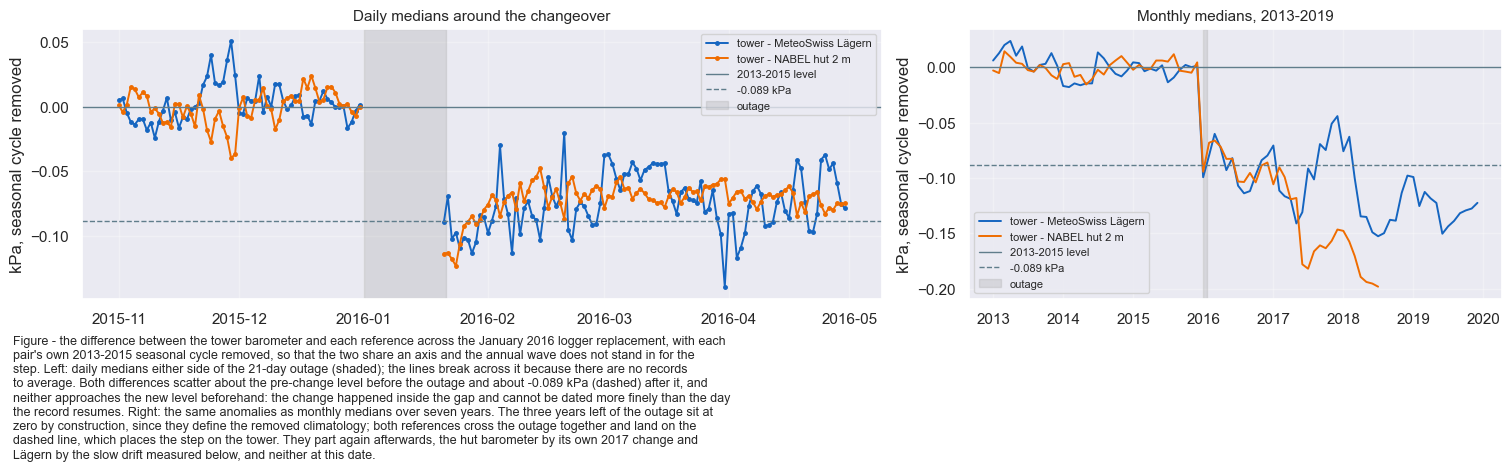

In [35]:
# The step at a resolution that separates it from a drift. Two things are removed first: the
# 1.7 kPa between the two differences, on which 0.09 kPa is a line thickness, and the annual wave
# of step 3, about as large as the step. Subtracting each pair's own monthly climatology over the
# three years before the changeover does both; the pre-change era then sits at zero by
# construction.
_CLIM_YEARS = slice(f'{BREAK_YEAR - 3}', f'{BREAK_YEAR - 1}')


def seasonal_anomaly(ref: str) -> pd.Series:
    """Tower minus `ref`, with that pair's own pre-change monthly climatology removed."""
    _full = pa_2005_2026[TARGET] - BAROMETERS[ref]
    _clim = _full.loc[_CLIM_YEARS].groupby(_full.loc[_CLIM_YEARS].index.month).median()
    return _full - _full.index.month.map(_clim)


fig, axs = plt.subplots(ncols=2, figsize=(15, 4.6), dpi=100, layout='constrained',
                        width_ratios=[1.5, 1])
for _ax, _win, _freq, _title in [
        (axs[0], slice(f'{BREAK_YEAR - 1}-11-01', f'{BREAK_YEAR}-04-30'), '1D',
         'Daily medians around the changeover'),
        (axs[1], slice(f'{BREAK_YEAR - 3}', f'{BREAK_YEAR + 3}'), 'MS',
         f'Monthly medians, {BREAK_YEAR - 3}-{BREAK_YEAR + 3}')]:
    for _ref, _colour in [(LAEGERN, '#1565C0'), (HUT, '#EF6C00')]:
        # No dropna: an empty bin stays NaN, so the line breaks at the outage instead of drawing a
        # straight segment across it that would look like the sensor moving during the gap.
        _d = seasonal_anomaly(_ref).loc[_win].resample(_freq).median()
        _ax.plot(_d.index, _d.values, lw=1.4, marker='o' if _freq == '1D' else None, ms=2.5,
                 color=_colour, label=f'tower - {_ref}')
    _ax.axhline(0, color='#607D8B', lw=1.0, label=f'{BREAK_YEAR - 3}-{BREAK_YEAR - 1} level')
    _ax.axhline(STEP_2016, color='#607D8B', lw=1.0, ls='--', label=f'{STEP_2016:+.3f} kPa')
    _ax.axvspan(OUTAGE_START, OUTAGE_END, color='#9E9E9E', alpha=.25, label='outage')
    _ax.set_ylabel('kPa, seasonal cycle removed')
    _ax.set_title(_title, fontsize=11)
    _ax.legend(fontsize=8)
    _ax.grid(alpha=.3)

figcap(fig, f"the difference between the tower barometer and each reference across the January "
            f"{BREAK_YEAR} logger replacement, with each pair's own "
            f"{BREAK_YEAR - 3}-{BREAK_YEAR - 1} seasonal cycle removed, so that the two share an "
            f"axis and the annual wave does not stand in for the step. Left: daily medians either "
            f"side of the {OUTAGE_DAYS:.0f}-day outage (shaded); the lines break across it because "
            f"there are no records to average. Both differences scatter about the pre-change level "
            f"before the outage and about {STEP_2016:+.3f} kPa (dashed) after it, and neither "
            f"approaches the new level beforehand: the change happened inside the gap and cannot be "
            f"dated more finely than the day the record resumes. Right: the same anomalies as "
            f"monthly medians over seven years. The three years left of the outage sit at zero by "
            f"construction, since they define the removed climatology; both references cross the "
            f"outage together and land on the dashed line, which places the step on the tower. They "
            f"part again afterwards, the hut barometer by its own {BREAK_YEAR + 1} change and "
            f"Lägern by the slow drift measured below, and neither at this date.")

The tower-minus-Lägern difference also falls slowly across the record. Without the two attributed
events (2010 at Lägern, 2016 here) a residual drift of the same order as the step remains, more than
half of it after the hut barometer stops, where it cannot be attributed.

#### 📋 Table: total change split into events and drift

In [36]:
_ms_by_year = diff_table[f'{TOWER} - {LAEGERN}']
_first, _last = int(_ms_by_year.index.min()), int(_ms_by_year.index.max())
_total = float(_ms_by_year.loc[_last] - _ms_by_year.loc[_first])
_events = {_y: float(change.loc[_y, f'{TOWER} - {LAEGERN}'])
           for _y, _who in ATTRIBUTED.items() if _who is not None}
_residual = _total - sum(_events.values())
_last_witness = int(pa_2005_2026[REFERENCE].last_valid_index().year)
_after = float(_ms_by_year.loc[_last] - _ms_by_year.loc[_last_witness])

tabcap("the total change in the tower-minus-Lägern difference over the full years of the record, "
       "split into the events the attribution rule identified and the remainder. The remainder is "
       "a drift without a date, so there is no boundary at which to correct it")
display(pd.DataFrame(
    {'kPa': {f'total, {_first} to {_last}': _total,
             **{f'attributed to {ATTRIBUTED[_y]} at {_y}': _v for _y, _v in _events.items()},
             'residual drift, unattributed': _residual,
             f'of which after {_last_witness}, with no second barometer': _after}}).round(4))

print(f"\nresidual drift over {_last - _first} years: {_residual:+.4f} kPa "
      f"({_residual / KPA_PER_METRE:+.0f} m of air), against a step of {STEP_2016:+.4f} kPa")
print(f"share of it falling after the hut barometer stops: {100 * _after / _residual:.0f} %")
assert abs(_residual) > abs(STEP_2016) / 2, (
    "the unattributed drift has become small beside the 2016 step, which removes one of the three "
    "reasons the callout below gives for not correcting the step")

Table - the total change in the tower-minus-Lägern difference over the full years of the record,
split into the events the attribution rule identified and the remainder. The remainder is a drift
without a date, so there is no boundary at which to correct it



,kPa
"total, 2006 to 2025",-0.2457
attributed to MeteoSwiss Lägern at 2011,-0.0561
attributed to tower 47 m at 2016,-0.0884
attributed to NABEL hut 2 m at 2017,-0.0034
"residual drift, unattributed",-0.0978
"of which after 2018, with no second barometer",-0.0520



residual drift over 19 years: -0.0978 kPa (-9 m of air), against a step of -0.0886 kPa
share of it falling after the hut barometer stops: 53 %


::: {.callout-important title="Why the step is reported and not corrected"}
The step is real, dated and attributed, and a correction would be defensible. It is not applied,
for three reasons in order of weight:

- **Size.** One part in a thousand of the value, under ten metres of air. Air density, and the
  fluxes computed from it, change by the same fraction.
- **Cost.** Homogenising means a second, rescaled column and a `SOURCE` flag, as in `02`, `08` and
  `09`. That changes this product and the merged product, a decision about the dataset rather than
  this variable.
- **Remainder.** The residual drift is of the same order, has no date at which to correct it, and
  after 2018 cannot be attributed. Homogenising would remove the step and leave the drift.

For one absolute level across the record, lower the records before `ACQUISITION_CHANGE` by the
size of the step printed above; keep the later era.
:::

### 6️⃣ No step at the December 2021 screening splice

`meteoscreening_mst` ends on 31 December 2021 and `meteoscreening_diive` begins the next day,
without overlap. This is a *screening* boundary: no fieldbook work on this sensor, no program change.
With the hut barometer gone, only the difference against MeteoSwiss is available, so the pattern
rule cannot be applied. The change across the splice is **smaller** than the median year-to-year
change, and the three-year statistic lies between its neighbours' values: slow drift, not a splice.

#### 📋 Table: change across the 2021/2022 screening splice

In [37]:
SCREENING_YEAR = 2022   # the first year screened by diive; mst ends on 31 Dec 2021
_ms_label = f'{TOWER} - {LAEGERN}'
_ms = diff_table[_ms_label]


def step_at(series: pd.Series, year: int, span: int = 3) -> float:
    """Change of a yearly difference across `year`, over `span` years either side, in kPa.

    The candidate year itself is excluded from both sides. Returns nan rather than a number when
    either side is thin, so a year at the edge of the record cannot win a comparison by having
    almost no data behind it.
    """
    _pre = series.reindex(range(year - span, year)).dropna()
    _post = series.reindex(range(year + 1, year + 1 + span)).dropna()
    if len(_pre) < 2 or len(_post) < 2:
        return float('nan')
    return float(_post.mean() - _pre.mean())


assert np.isnan(step_at(_ms, 1990)), "(!) step_at returned a number for a year off the record"
assert np.isnan(step_at(_ms, int(_ms.index.max()))), \
    "(!) step_at returned a number for the last year of the record"

_adjacent = _ms.diff()
_quiet_adjacent = _adjacent.drop(index=[_y for _y in (2011, 2016, 2017, SCREENING_YEAR)
                                        if _y in _adjacent.index]).abs()
tabcap(f"the tower-minus-Lägern difference at the {SCREENING_YEAR - 1}/{SCREENING_YEAR} screening "
       f"boundary and in the years around it. A step lands entirely in the one-year change; the "
       f"three-year change is dominated by the slow drift of this difference and is shown so the "
       f"two are not confused")
splice_table = pd.DataFrame({
    'one-year change (kPa)': {_y: _adjacent.get(_y, float('nan'))
                              for _y in range(SCREENING_YEAR - 2, SCREENING_YEAR + 3)},
    'three-year change (kPa)': {_y: step_at(_ms, _y)
                                for _y in range(SCREENING_YEAR - 2, SCREENING_YEAR + 3)},
})
splice_table.index.name = 'YEAR'
display(splice_table.round(4))

_here = float(_adjacent.loc[SCREENING_YEAR])
_typical_adj = float(_quiet_adjacent.median())
print(f"\nchange across the splice:            {_here:+.4f} kPa "
      f"({_here / KPA_PER_METRE:+.1f} m of air)")
print(f"median change in an ordinary year:   {_typical_adj:.4f} kPa")
print(f"change across the 2016 hardware date: {change.loc[BREAK_YEAR, _ms_label]:+.4f} kPa")
assert abs(_here) < EVENT_THRESHOLD, (
    f"the tower-Laegern difference now moves by {_here:+.4f} kPa across the screening splice, past "
    f"the {EVENT_THRESHOLD} kPa an event is counted at - the mst/diive splice can no longer be "
    f"reported as clean")
assert abs(_here) < _typical_adj, (
    "the change across the screening splice is no longer smaller than what this difference does in "
    "an ordinary year, which is the statement this step makes")
_neighbours = [step_at(_ms, _y) for _y in (SCREENING_YEAR - 1, SCREENING_YEAR + 1)]
assert min(_neighbours) <= step_at(_ms, SCREENING_YEAR) <= max(_neighbours), (
    "the three-year change at the splice is no longer between the values of its own neighbours, so "
    "it is no longer just the slow drift passing through")
print("\nNothing happens at the screening boundary that does not happen in an ordinary year. The "
      "two screenings of this measurement can be joined.")

Table - the tower-minus-Lägern difference at the 2021/2022 screening boundary and in the years
around it. A step lands entirely in the one-year change; the three-year change is dominated by the
slow drift of this difference and is shown so the two are not confused



,one-year change (kPa),three-year change (kPa)
YEAR,,
2020,-0.0199,-0.0388
2021,0.0002,-0.0262
2022,-0.0032,-0.0253
2023,-0.0115,-0.0197
2024,-0.0007,NaN



change across the splice:            -0.0032 kPa (-0.3 m of air)
median change in an ordinary year:   0.0062 kPa
change across the 2016 hardware date: -0.0884 kPa

Nothing happens at the screening boundary that does not happen in an ordinary year. The two screenings of this measurement can be joined.


### 7️⃣ What the maintenance record holds for this barometer

Two questions: what the fieldbook says about the barometer, and about the January 2016 changeover.
The barometer search returns one free-text entry, of 3 January 2023, which matches only on the word
"Vaisala" and concerns the PWD12 present-weather sensor. It is a false positive.

In [38]:
# The maintenance record, read and filtered here rather than quoted, so a newer export
# re-derives this instead of leaving a stale copy in the prose.
fb = pd.read_csv(FIELDBOOK)
fb['Date'] = pd.to_datetime(fb['Date'], format='%d.%m.%Y', errors='coerce')
fb['text'] = fb['Text'].apply(strip_html)
audit_unmapped_names(fb['text'], 'fieldbook entries')
print(f"fieldbook: {len(fb):,} entries, {fb['Date'].min().date()} -> {fb['Date'].max().date()}")
_dev = fb[['Device Name', 'Device Model']].astype(str).agg(' '.join, axis=1)

# Question 1: does this barometer appear at all? Device columns AND free text, because the entries
# that explain a fault are routinely filed under something else.
BAROMETER = r'PTB\s*-?\s*101|barometer|barometric|Vaisala|Luftdruck'
_by_device = _dev.str.contains(BAROMETER, case=False, regex=True, na=False)
_by_text = fb['text'].str.contains(BAROMETER, case=False, regex=True, na=False)
print(f"\nentries naming a barometer: {int(_by_device.sum())} by device column, "
      f"{int(_by_text.sum())} by free text")


def fragment(text, pattern, width=40) -> str:
    """The part of one entry that matches, rather than its first hundred characters.

    Several of these entries are whole-day visit reports in which the matching word appears once,
    halfway through; truncating from the start shows the drive to the site instead.
    """
    _m = re.search(pattern, str(text), re.I)
    if not _m:
        return str(text)[:2 * width]
    _lo, _hi = max(0, _m.start() - width), min(len(str(text)), _m.end() + width)
    return ('...' if _lo else '') + str(text)[_lo:_hi] + ('...' if _hi < len(str(text)) else '')


for _, _r in fb[_by_device | _by_text].sort_values('Date').iterrows():
    print(f"  {_r['Date'].date()} [{_r['Device Model']}] {fragment(_r['text'], BAROMETER)}")

assert int(_by_device.sum()) == 0, (
    "a barometer now appears in the device inventory, so the statement that this instrument is "
    "absent from the maintenance record is out of date")

# The word 'pressure' on its own is about something else here, and saying so is part of the
# answer: a filter that counted those would report maintenance on a sensor that has had none.
_pressure = fb['text'].str.contains(r'\bpressure\b|\bDruck\w*', case=False, regex=True, na=False)
print(f"\nentries containing the word 'pressure' or 'Druck': {int(_pressure.sum())}, none of them "
      f"about this instrument. What they are about:")
_ctx = sorted({_m.group(0).strip().lower()
               for _t in fb.loc[_pressure, 'text']
               for _m in re.finditer(r'(?:\w+\s+){0,2}(?:pressure|Druck\w*)', str(_t), re.I)})
print(textwrap.fill('; '.join(_ctx[:24]), 110))
assert not fb.loc[_pressure, 'text'].str.contains(
    r'(?:replac|calibrat|clean)\w*\s+(?:the\s+)?(?:PTB|barometer|pressure sensor)',
    case=False, regex=True, na=False).any(), (
    "the fieldbook now records work on the barometer itself, which the sections above and the "
    "documentation page both state does not exist")
print("\nIn twenty-one years the barometer is never named: not replaced, not calibrated, not "
      "cleaned, and not in the device inventory. Every occurrence of the word 'pressure' is about "
      "a gas cylinder, a flow regulator or an analyser.")

  fieldbook entries: no unmapped name-shaped tokens (58 allowlisted terms)
fieldbook: 2,133 entries, 2003-10-24 -> 2026-10-16

entries naming a barometer: 0 by device column, 1 by free text
  2023-01-03 [na] ...data acquisition of the PWD12 using the vaisala script of person 20. The sensor was ins...

entries containing the word 'pressure' or 'Druck': 23, none of them about this instrument. What they are about:
ansaugstellen mit druckluft; aufgrund der druckabhaengigkeit; but pressure; check tank pressure; checking tank
pressure; der druckabfall; die druckdifferenz; druck; drucks; ein deutlicher drucksprung; flush the pressure;
gas tank pressure; initial pressure; low level pressure; more stable pressure; of the pressure; pressure;
profil druckabhaengigkeit; reference flask pressure; relativ grosser drucksprung; the cell pressure; the
internal pressure; the pressure; und ungenauen druckkompensation

In twenty-one years the barometer is never named: not replaced, not calibrated, not cle

#### 📋 Table: fieldbook entries on the tower logger, winter 2015/16

In [39]:
# Question 2: what the record holds for the January 2016 acquisition change. Entries dated
# 1 January 2016 are the GIN inventory import rather than events and are excluded, as elsewhere.
TOWER_LOGGER = r'iDL_T1_47_1|CR1000_T1_47_1|CH-LAE_T1_47'
_win = fb[fb['Date'].between(f'{BREAK_YEAR - 1}-12-01', f'{BREAK_YEAR}-03-31')
          & (fb['Date'] != f'{BREAK_YEAR}-01-01')]
_hits = _win[_win['text'].str.contains(TOWER_LOGGER, regex=True, na=False)
             | _dev.reindex(_win.index).str.contains(TOWER_LOGGER, regex=True, na=False)
             | _win['Operation Tag'].astype(str).str.contains(TOWER_LOGGER, regex=True, na=False)
             | _win['Location'].astype(str).str.contains(TOWER_LOGGER, regex=True, na=False)]
assert len(_hits) > 0, (
    "no fieldbook entries at all for the tower logger around the changeover - has the export "
    "format changed?")

tabcap(f"every fieldbook entry naming the tower logger from December {BREAK_YEAR - 1} to March "
       f"{BREAK_YEAR}, shown around the words that name it. Inventory rows dated 1 January are the "
       f"GIN import rather than events and are excluded")
_show = _hits[['Date', 'Device Model', 'Operation Tag', 'text']].copy()
_show['Date'] = _show['Date'].dt.date
_show['text'] = _show['text'].apply(lambda _t: fragment(_t, TOWER_LOGGER, width=70))
with pd.option_context('display.max_colwidth', 150):
    display(_show.set_index('Date'))

# The program on disk carries a version date in its folder name. If the fieldbook names the same
# file, then the program this notebook parsed is the program that was actually running.
PROGRAM_VERSION = re.search(r'(\d{8})', Path(PROGRAM_AFTER).parent.name).group(1)
_named = _hits[_hits['text'].str.contains(PROGRAM_VERSION, na=False)]
print(f"\nprogram folder on disk carries version {PROGRAM_VERSION} "
      f"({pd.Timestamp(PROGRAM_VERSION):%d %b %Y})")
print(f"fieldbook entries naming that version: {len(_named)}")
for _, _r in _named.iterrows():
    print(f"  {_r['Date'].date()}  {fragment(_r['text'], PROGRAM_VERSION, width=70)}")
assert len(_named) > 0, (
    "the fieldbook no longer names the logger program version this notebook parses, so the "
    "identification of the program that was running at the changeover rests on the file name alone")
assert pd.Timestamp(PROGRAM_VERSION) < pd.Timestamp(ACQUISITION_CHANGE), (
    "the logger program on disk is dated after the record resumes, so it cannot be the program "
    "that produced the first values of the later era")
print(f"\nThe program parsed above is dated "
      f"{(pd.Timestamp(ACQUISITION_CHANGE) - pd.Timestamp(PROGRAM_VERSION)).days} days before "
      f"the record resumes, and the fieldbook names that same file. The record, the program "
      f"and the maintenance log agree on the date without having been made to.")

Table - every fieldbook entry naming the tower logger from December 2015 to March 2016, shown around
the words that name it. Inventory rows dated 1 January are the GIN import rather than events and are
excluded



,Device Model,Operation Tag,text
Date,,,
2016-02-10,CR1000,CH-LAE_iDL_T1_47_1,Added device to site.
2016-02-10,na,na,...loaded logger data to avoid data gaps data download for tower logger iCR1000_T1_47_1 was interrupted but could downloaded using loggernet (pakb...
2016-01-27,na,na,... to SC raspi –> ok downloaded the tablefiles from the ““meteologger”” iDL_T1_47_1



program folder on disk carries version 20160118 (18 Jan 2016)
fieldbook entries naming that version: 1
  2016-02-10  ...estarted logger and uploaded the logger program CH-LAE_CR1000_T1_47_1-20160118.CR1 again. Everything back to normal. With the data files on the emeb...

The program parsed above is dated 3 days before the record resumes, and the fieldbook names that same file. The record, the program and the maintenance log agree on the date without having been made to.


#### What this section settles

`PA_T1_47_1` is **one instrument over the whole record**, a Vaisala PTB101B with one conversion,
never replaced, calibrated or cleaned according to the fieldbook. Its **absolute level is right**:
the barometric formula, with nothing fitted, places it within a few metres of where it hangs from
both references and reproduces the seasonal shape of the difference.

The record is **not homogeneous**: it steps by about 0.09 kPa at the January 2016 acquisition change,
on the tower, and the later era agrees with the physics on average over 2016 to 2025. It is exported as measured (callout above).
The **December 2021 screening splice is clean**.

***

### 📋 Table: working frame after the corrections

In [40]:
tabcap("the working dataframe after every correction, and the distribution of both columns. The reference column is diagnostic and is dropped before export")
display(pa_2005_2026)
pa_2005_2026.describe()

Table - the working dataframe after every correction, and the distribution of both columns. The
reference column is diagnostic and is dropped before export



,PA_T1_47_1,PA_NABEL_H1_2_1
TIMESTAMP_MIDDLE,,
2005-09-02 00:15:00,NaN,94.184167
2005-09-02 00:45:00,NaN,94.197500
2005-09-02 01:15:00,NaN,94.210833
2005-09-02 01:45:00,NaN,94.227500
2005-09-02 02:15:00,NaN,94.220833
...,...,...
2026-09-30 21:45:00,93.616374,NaN
2026-09-30 22:15:00,93.619444,NaN
2026-09-30 22:45:00,93.620568,NaN


,PA_T1_47_1,PA_NABEL_H1_2_1
count,365542.000000,224449.000000
mean,93.227471,93.661485
std,0.740692,0.748588
min,89.446007,89.786333
25%,92.850873,93.261600
50%,93.306000,93.738947
75%,93.693309,94.146000
max,95.543335,96.029917


***

## 🚫 No gap-filling here

Unlike `01`-`03`, this product is not gap-filled. Pressure would be easy to fill (smooth,
autocorrelated, tracked by a nearby barometer), which is why the decision is recorded: a filled `PA`
would be indistinguishable from a measured one without a flag, and this product ships only
measurements. The numbers below are computed, not quoted.

### 📋 Table: missing records by gap length

In [41]:
_missing = pa_2005_2026[TARGET].isna()
_runs = _missing.groupby((~_missing).cumsum()).transform('sum').where(_missing, 0)
_gap_lengths = pd.Series([int(_g) for _g in _runs[_missing].groupby((~_missing).cumsum()).max()])

print(f"records:            {len(pa_2005_2026):,}")
print(f"measured:           {int((~_missing).sum()):,} ({100 * (~_missing).mean():.2f} %)")
print(f"missing:            {int(_missing.sum()):,} ({100 * _missing.mean():.2f} %)")
print(f"separate gaps:      {len(_gap_lengths):,}")
print(f"of those, <= 1 h:   {int((_gap_lengths <= 2).sum()):,}")
print(f"longest gap:        {int(_gap_lengths.max()):,} records "
      f"({_gap_lengths.max() / 48:.1f} days)")

tabcap("how the missing half-hours are distributed over gap lengths. Most gaps are short and most "
       "missing records are in a few long ones, the distinction that matters for anyone deciding "
       "whether to interpolate")
_bins = pd.cut(_gap_lengths, [0, 2, 12, 48, 480, 10 ** 6],
               labels=['<= 1 h', '1-6 h', '6-24 h', '1-10 d', '> 10 d'])
_gapsum = pd.DataFrame({'gaps': _gap_lengths.groupby(_bins, observed=False).count(),
                        'records lost': _gap_lengths.groupby(_bins, observed=False).sum()})
_gapsum['% of all missing'] = (100 * _gapsum['records lost'] / int(_missing.sum())).round(1)
display(_gapsum)

records:            369,552
measured:           365,542 (98.91 %)
missing:            4,010 (1.09 %)
separate gaps:      415
of those, <= 1 h:   399
longest gap:        988 records (20.6 days)
Table - how the missing half-hours are distributed over gap lengths. Most gaps are short and most
missing records are in a few long ones, the distinction that matters for anyone deciding whether to
interpolate



,gaps,records lost,% of all missing
<= 1 h,399,413,10.3
1-6 h,5,26,0.6
6-24 h,3,50,1.2
1-10 d,4,766,19.1
> 10 d,4,2755,68.7


Consequences for users of this file:

- `PA_T1_47_1` **contains `NaN`**; handle the gaps explicitly.
- **No `FLAG_..._ISFILLED` column**: non-null means measured.
- **No `_HOMOGENIZED` column**, although the record steps in January 2016; apply the step yourself
  if one absolute level is needed (see the corrections section).
- If a complete series is needed, fill it downstream, where the fill can be flagged.

***

## ➡️ Prepare dataframe for export

In [42]:
VALCOL = TARGET

export_df = pa_2005_2026[[VALCOL]].copy()   # the NABEL reference is diagnostic only, not exported
export_df

,PA_T1_47_1
TIMESTAMP_MIDDLE,
2005-09-02 00:15:00,NaN
2005-09-02 00:45:00,NaN
2005-09-02 01:15:00,NaN
2005-09-02 01:45:00,NaN
2005-09-02 02:15:00,NaN
...,...
2026-09-30 21:45:00,93.616374
2026-09-30 22:15:00,93.619444
2026-09-30 22:45:00,93.620568


Sanity check. The series is **not** expected to be complete. The checks: a continuous index
without duplicates ending at `PERIOD_END`, and values that are all plausible pressure in kPa, the
last defence against a unit error reaching the file.

### 📋 Table: distribution of the exported column

In [43]:
_lo, _hi = PA_PLAUSIBLE_KPA

print(f"Records:          {len(export_df):,}")
print(f"Measured:         {int(export_df[VALCOL].notna().sum()):,} "
      f"({100 * export_df[VALCOL].notna().mean():.2f}%)")
print(f"Missing (NaN):    {int(export_df[VALCOL].isnull().sum()):,} "
      f"({100 * export_df[VALCOL].isna().mean():.2f}%)")
print(f"Duplicate index:  {int(export_df.index.duplicated().sum())}")
print(f"Index gaps:       "
      f"{int((export_df.index.to_series().diff().dropna() != pd.Timedelta('30min')).sum())}")
print(f"Index:            {export_df.index[0]} -> {export_df.index[-1]}")
print(f"Min / max:        {export_df[VALCOL].min():.3f} / {export_df[VALCOL].max():.3f} kPa")

# Hard guards: every one of these would indicate a serious problem.
assert export_df.index.duplicated().sum() == 0, "duplicate timestamps"
assert (export_df.index.to_series().diff().dropna() == pd.Timedelta('30min')).all(), \
    "index not continuous 30MIN"
assert export_df[VALCOL].min() >= _lo and export_df[VALCOL].max() <= _hi, \
    f"values outside {_lo}-{_hi} kPa - possible unit error"
assert export_df[VALCOL].notna().any(), "no data at all"
assert export_df.index[-1] == pd.Timestamp(PERIOD_END), (
    f"the export ends at {export_df.index[-1]}, not at PERIOD_END ({PERIOD_END})")
assert export_df[VALCOL].loc[str(LAST_FULL_YEAR + 1)].notna().any(), (
    f"no measured value after {LAST_FULL_YEAR}: the extension to {PERIOD_END} did not arrive")
print("\nAll checks passed.")

tabcap("the distribution of the exported column. `count` is the number of measured records, not "
       "the length of the file")
export_df.describe()

Records:          369,552
Measured:         365,542 (98.91%)
Missing (NaN):    4,010 (1.09%)
Duplicate index:  0
Index gaps:       0
Index:            2005-09-02 00:15:00 -> 2026-09-30 23:45:00
Min / max:        89.446 / 95.543 kPa

All checks passed.
Table - the distribution of the exported column. `count` is the number of measured records, not the
length of the file



,PA_T1_47_1
count,365542.000000
mean,93.227471
std,0.740692
min,89.446007
25%,92.850873
50%,93.306000
75%,93.693309
max,95.543335


### Per-year statistics

Every yearly **median** must sit at ~93 kPa with no step at the 2021/2022 source boundary; ~93,000
or ~930 would mean an unconverted source. In `coverage_%`, 2012 holds the removed fault periods, and
2009, 2016 and 2019 have sensor outages (in 2009 a 9.8-day outage in August). 2005 (from
2 September) and 2026 (to September) are partial, marked in `partial`; the interannual spread is
computed to `LAST_FULL_YEAR` and includes the partial 2005.

#### 📋 Table: the exported column per year

In [44]:
_yr = export_df[VALCOL].groupby(export_df.index.year).agg(['count', 'median', 'min', 'max', 'std'])
_yr['possible'] = export_df[VALCOL].groupby(export_df.index.year).size()
_yr['coverage_%'] = (100 * _yr['count'] / _yr['possible']).round(2)
# A year whose index is shorter than the calendar year: 2005 starts on 2 September, 2026 ends with
# September.
_yr['partial'] = _yr['possible'] < [48 * (366 if pd.Timestamp(f'{_y}-01-01').is_leap_year else 365)
                                    for _y in _yr.index]
_yr['source'] = np.where(_yr.index <= 2021, 'mst', 'diive')
_yr['acquisition'] = np.where(_yr.index < pd.Timestamp(ACQUISITION_CHANGE).year, 'CR10X',
                             'CR1000')
tabcap(f"the exported column year by year: records carrying a value, their share of the year, and "
       f"the level. The median checks the unit harmonisation, since every year has to sit at about "
       f"93 kPa. The last columns give the screening and acquisition system of each year, and "
       f"`partial` marks the years the record covers only in part "
       f"({', '.join(str(_y) for _y in _yr.index[_yr['partial'].to_numpy()])})")
display(_yr.round(3))

# The harmonisation check, stated as an assertion rather than left to the eye.
_med = _yr['median']
assert ((_med > 85) & (_med < 100)).all(), \
    f"a yearly median is outside 85-100 kPa: {_med[(_med <= 85) | (_med >= 100)].to_dict()}"
print(f"All yearly medians between {_med.min():.3f} and {_med.max():.3f} kPa "
      f"(spread {_med.max() - _med.min():.3f} kPa) - no unit break survives.")

_step = abs(float(_med.loc[2022]) - float(_med.loc[2021]))
print(f"step across the 2021/2022 source boundary: {_step:.3f} kPa "
      f"(interannual spread to {LAST_FULL_YEAR} is {float(_med.loc[:LAST_FULL_YEAR].std()):.3f} kPa, "
      f"so this is ordinary weather)")

Table - the exported column year by year: records carrying a value, their share of the year, and the
level. The median checks the unit harmonisation, since every year has to sit at about 93 kPa. The
last columns give the screening and acquisition system of each year, and `partial` marks the years
the record covers only in part (2005, 2026)



,count,median,min,max,std,possible,coverage_%,partial,source,acquisition
TIMESTAMP_MIDDLE,,,,,,,,,,
2005,5774,93.584,91.040,94.995,0.771,5808,99.41,True,mst,CR10X
2006,17445,93.405,90.990,94.954,0.679,17520,99.57,False,mst,CR10X
2007,17461,93.420,90.691,95.066,0.674,17520,99.66,False,mst,CR10X
2008,17492,93.293,90.244,95.323,0.824,17568,99.57,False,mst,CR10X
2009,17000,93.309,89.574,94.611,0.798,17520,97.03,False,mst,CR10X
2010,17323,93.096,89.740,94.513,0.775,17520,98.88,False,mst,CR10X
2011,17488,93.460,90.045,95.169,0.611,17520,99.82,False,mst,CR10X
2012,16539,93.377,90.740,94.952,0.689,17568,94.14,False,mst,CR10X
2013,17447,93.328,90.524,95.210,0.797,17520,99.58,False,mst,CR10X


All yearly medians between 93.096 and 93.584 kPa (spread 0.488 kPa) - no unit break survives.
step across the 2021/2022 source boundary: 0.065 kPa (interannual spread to 2025 is 0.127 kPa, so this is ordinary weather)


#### 📊 Plot: heatmap and yearly level of the export

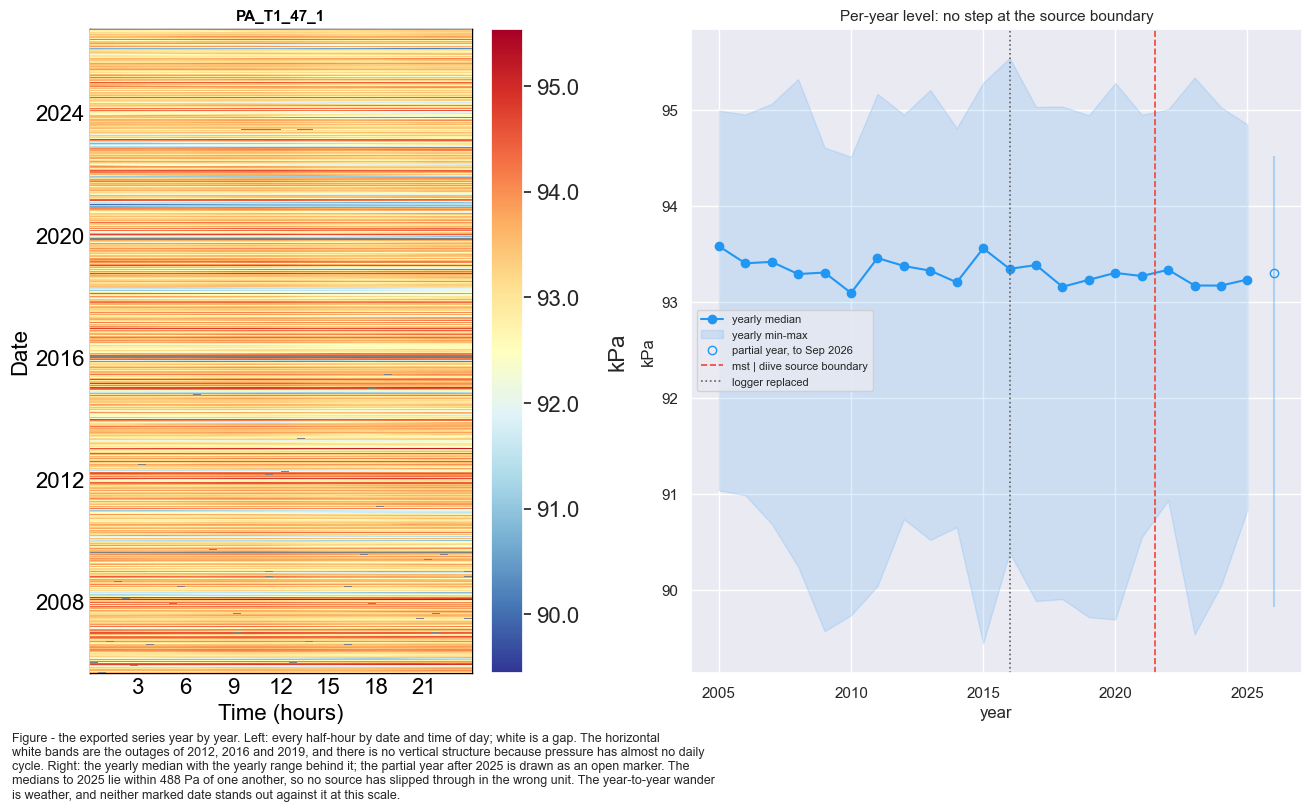

In [45]:
fig, axs = plt.subplots(ncols=2, figsize=(13, 8), dpi=100, layout='constrained',
                        width_ratios=[1, 1.6])
dv.plotting.HeatmapDateTime(series=export_df[VALCOL]).plot(
    ax=axs[0], cb_digits_after_comma=1, zlabel='kPa',
    format_style=dv.plotting.FormatStyle(title=VALCOL, title_fontsize=11))

_full = _yr.loc[:LAST_FULL_YEAR]
_part = _yr.loc[LAST_FULL_YEAR + 1:]
_full['median'].plot(ax=axs[1], marker='o', color='#2196F3', label='yearly median')
axs[1].fill_between(_full.index, _full['min'], _full['max'], color='#2196F3', alpha=.15,
                    label='yearly min-max')
axs[1].plot(_part.index, _part['median'], marker='o', mfc='none', ls='none', color='#2196F3',
            label=f'partial year, to {pd.Timestamp(PERIOD_END):%b %Y}')
axs[1].vlines(_part.index, _part['min'], _part['max'], color='#2196F3', alpha=.3)
axs[1].axvline(2021.5, color='#F44336', ls='--', lw=1.2, label='mst | diive source boundary')
axs[1].set_ylabel('kPa')
axs[1].set_xlabel('year')
axs[1].set_title('Per-year level: no step at the source boundary', fontsize=11)
axs[1].axvline(pd.Timestamp(ACQUISITION_CHANGE).year, color='#616161', ls=':', lw=1.2,
               label='logger replaced')
axs[1].legend(fontsize=8)
figcap(fig, f"the exported series year by year. Left: every half-hour by date and time of day; "
            f"white is a gap. The horizontal white bands are the outages of 2009, 2012, 2016 and 2019, "
            f"and there is no vertical structure because pressure has almost no daily cycle. Right: "
            f"the yearly median with the yearly range behind it; the partial year after "
            f"{LAST_FULL_YEAR} is drawn as an open marker. The medians to {LAST_FULL_YEAR} lie "
            f"within {1000 * float(_full['median'].max() - _full['median'].min()):.0f} Pa of one "
            f"another, the partial 2005 setting the highest of them, so no source has slipped "
            f"through in the wrong unit. The year-to-year wander "
            f"is weather, and neither marked date stands out against it at this scale.")

***

## 💾 Save to file

In [46]:
filepath = dv.save_parquet(filename=OUTNAME, data=export_df, outpath=OUTPATH)
export_df.to_csv(Path(OUTPATH) / f"{OUTNAME}.csv")
print(f"Saved to: {filepath}")

> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\05_METEO_PA_2005-2026.09.parquet (0.096 seconds).

Saved to: F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS\05_METEO_PA_2005-2026.09.parquet


### Verify the written file

The parquet is read back and checked directly.

#### 📋 Table: yearly median from the written file

In [47]:
_written = dv.load_parquet(filepath=str(Path(OUTPATH) / f"{OUTNAME}.parquet"))

print(f"columns:   {list(_written.columns)}")
print(f"index:     {_written.index[0]} -> {_written.index[-1]}  ({len(_written):,} records)")
print(f"measured:  {int(_written[VALCOL].notna().sum()):,} "
      f"({100 * _written[VALCOL].notna().mean():.2f}%)")
print(f"median:    {float(_written[VALCOL].median()):.3f} kPa")
print(f"min / max: {float(_written[VALCOL].min()):.3f} / {float(_written[VALCOL].max()):.3f} kPa")

assert list(_written.columns) == [VALCOL], "unexpected columns in the written file"
assert len(_written) == len(export_df), "record count changed on write"
assert _written[VALCOL].notna().sum() == export_df[VALCOL].notna().sum(), \
    "measured count changed on write"
assert 85 < float(_written[VALCOL].median()) < 100, "median outside plausible kPa range"
print("\nWritten file verified.")

tabcap(f"the yearly median of the column as written to the parquet file, read back from disk rather "
       f"than taken from the frame in memory. The last year ends at {PERIOD_END} and is partial")
display(_written[VALCOL].groupby(_written.index.year).median().round(3)
        .rename('yearly median (kPa)'))

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\05_METEO_PA_2005-2026.09.parquet (0.022 seconds).

columns:   ['PA_T1_47_1']
index:     2005-09-02 00:15:00 -> 2026-09-30 23:45:00  (369,552 records)
measured:  365,542 (98.91%)
median:    93.306 kPa
min / max: 89.446 / 95.543 kPa

Written file verified.
Table - the yearly median of the column as written to the parquet file, read back from disk rather
than taken from the frame in memory. The last year ends at 2026-09-30 23:45:00 and is partial



TIMESTAMP_MIDDLE
2005    93.584
2006    93.405
2007    93.420
2008    93.293
2009    93.309
2010    93.096
2011    93.460
2012    93.377
2013    93.328
2014    93.207
2015    93.561
2016    93.347
2017    93.387
2018    93.160
2019    93.234
2020    93.305
2021    93.272
2022    93.338
2023    93.174
2024    93.173
2025    93.236
2026    93.302
Name: yearly median (kPa), dtype: float64

***

## End of notebook.

In [48]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-22 15:54:09
Finished: 2026-10-22 15:55:50
Runtime:  00:01:41 (hh:mm:ss)
